# AI-Based Human Pose Estimation Using Five IMU Sensors

**Final Year Research Project**

This notebook trains deep learning models to predict **MediaPipe-style pose landmarks**
(a 17-keypoint body subset, 3D each = 51 values) from **five BMI160 IMU sensors** (accelerometer +
gyroscope, 6 channels each = 30 values), synchronized frame-by-frame.

**Pipeline overview**

1. Load and inspect the raw synchronized CSV
2. Exploratory Data Analysis (EDA)
3. Data cleaning and synchronization checks
4. Feature engineering (auto-detect IMU vs. pose columns)
5. Time-ordered train / validation / test split (no leakage)
6. Normalization (scalers fit on train only)
7. Sliding-window sequence construction
8. Five models: MLP baseline, 1D-CNN baseline, GRU, LSTM, Transformer encoder
9. Training with EarlyStopping / ReduceLROnPlateau / ModelCheckpoint / TensorBoard
10. Evaluation: MAE, MSE, RMSE, R², MPJPE, inference FPS
11. Rich visualizations, including 3D skeleton animation
12. Model comparison and ranking
13. Explainability via permutation importance
14. Saving all artifacts (models, scalers, metrics, predictions)
15. A ready-to-use inference function for new IMU recordings
16. Final discussion, limitations and future work




## 1. Imports, Configuration & Reproducibility

In [1]:
# ----------------------------------------------------------------------------------
# Core libraries
# ----------------------------------------------------------------------------------
import os
import json
import time
import random
import warnings
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.animation as animation
import seaborn as sns

from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
from IPython.display import display, Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------------------
# Reproducibility
# ----------------------------------------------------------------------------------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ----------------------------------------------------------------------------------
# GPU detection / mixed precision (only enabled automatically if a GPU is present)
# ----------------------------------------------------------------------------------
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
    # NOTE: mixed precision is deliberately NOT enabled. These models are tiny (<150k params), so
    # float16 gives no speed-up, but it makes the regression output layer float16 (~3 significant
    # digits), which adds noise to standardised pose targets.
    print(f"GPU(s) detected: {[g.name for g in gpus]}. Using float32.")
else:
    print("No GPU detected: running on CPU in float32.")

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

# ----------------------------------------------------------------------------------
# Project folders (created in the current working directory)
# ----------------------------------------------------------------------------------
DATA_PATH   = "/kaggle/input/datasets/bahasurunayanakantha/p123456/p1_20261020-221253.csv"   # Kaggle path; edit if running elsewhere
if not os.path.exists(DATA_PATH):
    import glob
    _found = sorted(glob.glob("*.csv") + glob.glob("/kaggle/input/**/*.csv", recursive=True))
    if not _found:
        raise FileNotFoundError(f"CSV not found at DATA_PATH={DATA_PATH!r} and no .csv file found nearby.")
    DATA_PATH = _found[0]
    print("DATA_PATH not found, using:", DATA_PATH)
DIR_FIGURES = "figures"
DIR_MODELS  = "saved_models"
DIR_SCALERS = "saved_scalers"
DIR_RESULTS = "results"
DIR_LOGS    = "logs/tensorboard"

for d in [DIR_FIGURES, DIR_MODELS, DIR_SCALERS, DIR_RESULTS, DIR_LOGS]:
    os.makedirs(d, exist_ok=True)

# ----------------------------------------------------------------------------------
# Plot style — publication-quality defaults
# ----------------------------------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
sns.set_style("whitegrid")

def savefig(name):
    #Save the current matplotlib figure into the figures folder at high resolution.
    path = os.path.join(DIR_FIGURES, name)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path}")


GPU(s) detected: ['/physical_device:GPU:0', '/physical_device:GPU:1']. Using float32.
TensorFlow version: 2.20.0
Keras version: 3.13.2


## 2. Load Dataset

The dataset is one CSV file where each row is a synchronized timestamp containing:

- `sys_time`: Unix timestamp of the frame
- `cv_0_x ... cv_16_z`: 17 MediaPipe-style pose landmarks x/y/z (**51 target columns**)
- `ESP32_IMU_1_ax ... ESP32_IMU_5_gz`: 5 IMU sensors x 6 channels (**30 input columns**)


In [2]:
df = pd.read_csv(DATA_PATH)
df = df.sort_values("sys_time").reset_index(drop=True)   # chronological order before any EDA / diff() check

print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\n--- head() ---")
display(df.head())

print("\n--- tail() ---")
display(df.tail())

print("\n--- info() ---")
df.info()


Shape (rows, columns): (2468, 83)

Column names:
['sys_time', 'local_time', 'cv_0_x', 'cv_0_y', 'cv_0_z', 'cv_1_x', 'cv_1_y', 'cv_1_z', 'cv_2_x', 'cv_2_y', 'cv_2_z', 'cv_3_x', 'cv_3_y', 'cv_3_z', 'cv_4_x', 'cv_4_y', 'cv_4_z', 'cv_5_x', 'cv_5_y', 'cv_5_z', 'cv_6_x', 'cv_6_y', 'cv_6_z', 'cv_7_x', 'cv_7_y', 'cv_7_z', 'cv_8_x', 'cv_8_y', 'cv_8_z', 'cv_9_x', 'cv_9_y', 'cv_9_z', 'cv_10_x', 'cv_10_y', 'cv_10_z', 'cv_11_x', 'cv_11_y', 'cv_11_z', 'cv_12_x', 'cv_12_y', 'cv_12_z', 'cv_13_x', 'cv_13_y', 'cv_13_z', 'cv_14_x', 'cv_14_y', 'cv_14_z', 'cv_15_x', 'cv_15_y', 'cv_15_z', 'cv_16_x', 'cv_16_y', 'cv_16_z', 'ESP32_IMU_1_ax', 'ESP32_IMU_1_ay', 'ESP32_IMU_1_az', 'ESP32_IMU_1_gx', 'ESP32_IMU_1_gy', 'ESP32_IMU_1_gz', 'ESP32_IMU_2_ax', 'ESP32_IMU_2_ay', 'ESP32_IMU_2_az', 'ESP32_IMU_2_gx', 'ESP32_IMU_2_gy', 'ESP32_IMU_2_gz', 'ESP32_IMU_3_ax', 'ESP32_IMU_3_ay', 'ESP32_IMU_3_az', 'ESP32_IMU_3_gx', 'ESP32_IMU_3_gy', 'ESP32_IMU_3_gz', 'ESP32_IMU_4_ax', 'ESP32_IMU_4_ay', 'ESP32_IMU_4_az', 'ESP32_IMU_4_gx

,sys_time,local_time,cv_0_x,cv_0_y,cv_0_z,cv_1_x,cv_1_y,cv_1_z,cv_2_x,cv_2_y,...,ESP32_IMU_4_az,ESP32_IMU_4_gx,ESP32_IMU_4_gy,ESP32_IMU_4_gz,ESP32_IMU_5_ax,ESP32_IMU_5_ay,ESP32_IMU_5_az,ESP32_IMU_5_gx,ESP32_IMU_5_gy,ESP32_IMU_5_gz
0,1.792515e+09,2026-10-20 22:12:53.901093,-0.0189,0.6166,-0.2582,0.1593,0.4435,-0.1594,-0.1689,0.4312,...,0.10376,0.0204,0.0392,0.0000,0.0584,-0.9814,-0.1986,0.026,0.024,-0.020
1,1.792515e+09,2026-10-20 22:12:53.951092,-0.0189,0.6166,-0.2582,0.1593,0.4435,-0.1594,-0.1689,0.4312,...,0.07544,0.0300,0.0196,0.0004,0.0562,-0.9780,-0.1964,0.024,0.030,-0.016
2,1.792515e+09,2026-10-20 22:12:54.001092,-0.0189,0.6114,-0.2803,0.1593,0.4370,-0.1797,-0.1688,0.4241,...,0.10908,0.0296,0.0104,0.0096,0.0492,-0.9790,-0.2022,0.030,0.022,-0.018
3,1.792515e+09,2026-10-20 22:12:54.051093,-0.0189,0.6114,-0.2803,0.1593,0.4370,-0.1797,-0.1688,0.4241,...,0.08736,0.0196,0.0196,0.0000,0.0486,-0.9772,-0.1950,0.026,0.014,-0.022
4,1.792515e+09,2026-10-20 22:12:54.101093,-0.0189,0.6104,-0.2839,0.1587,0.4346,-0.1867,-0.1688,0.4212,...,0.09644,0.0100,0.0100,0.0008,0.0572,-0.9790,-0.1844,0.020,0.012,-0.006



--- tail() ---


,sys_time,local_time,cv_0_x,cv_0_y,cv_0_z,cv_1_x,cv_1_y,cv_1_z,cv_2_x,cv_2_y,...,ESP32_IMU_4_az,ESP32_IMU_4_gx,ESP32_IMU_4_gy,ESP32_IMU_4_gz,ESP32_IMU_5_ax,ESP32_IMU_5_ay,ESP32_IMU_5_az,ESP32_IMU_5_gx,ESP32_IMU_5_gy,ESP32_IMU_5_gz
2463,1.792515e+09,2026-10-20 22:14:57.051093,-0.0089,0.6245,-0.2443,0.1717,0.4420,-0.1591,-0.1595,0.4417,...,0.0946,0.006,0.002,0.000,0.04398,-0.97356,-0.19382,0.0000,0.0018,-0.0046
2464,1.792515e+09,2026-10-20 22:14:57.101093,-0.0085,0.6252,-0.2443,0.1721,0.4428,-0.1590,-0.1593,0.4423,...,0.0892,0.002,0.024,0.000,0.04886,-0.97006,-0.19372,-0.0018,0.0136,0.0182
2465,1.792515e+09,2026-10-20 22:14:57.151093,-0.0086,0.6253,-0.2381,0.1721,0.4431,-0.1533,-0.1593,0.4426,...,0.0888,0.016,0.014,0.008,0.03198,-0.98292,-0.20042,-0.0082,0.0264,0.0100
2466,1.792515e+09,2026-10-20 22:14:57.201092,-0.0086,0.6253,-0.2381,0.1721,0.4431,-0.1533,-0.1593,0.4426,...,0.0738,0.012,0.026,0.010,0.04172,-0.97836,-0.20790,-0.0018,0.0154,0.0064
2467,1.792515e+09,2026-10-20 22:14:57.251092,-0.0090,0.6242,-0.2430,0.1717,0.4430,-0.1569,-0.1592,0.4410,...,0.0756,0.010,0.038,-0.006,0.04464,-0.97856,-0.17856,-0.0082,0.0310,-0.0118



--- info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2468 entries, 0 to 2467
Data columns (total 83 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sys_time        2468 non-null   float64
 1   local_time      2468 non-null   object 
 2   cv_0_x          2468 non-null   float64
 3   cv_0_y          2468 non-null   float64
 4   cv_0_z          2468 non-null   float64
 5   cv_1_x          2468 non-null   float64
 6   cv_1_y          2468 non-null   float64
 7   cv_1_z          2468 non-null   float64
 8   cv_2_x          2468 non-null   float64
 9   cv_2_y          2468 non-null   float64
 10  cv_2_z          2468 non-null   float64
 11  cv_3_x          2468 non-null   float64
 12  cv_3_y          2468 non-null   float64
 13  cv_3_z          2468 non-null   float64
 14  cv_4_x          2468 non-null   float64
 15  cv_4_y          2468 non-null   float64
 16  cv_4_z          2468 non-null   float64
 17  cv_5_x          2

In [3]:
print("Missing values per column (only columns with >0 shown):")
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing if len(missing) else "None — dataset has zero missing values.")

n_dupes = df.duplicated().sum()
print(f"\nDuplicate rows: {n_dupes}")

print("\nDescriptive statistics (all columns):")
display(df.describe().T)


Missing values per column (only columns with >0 shown):
ESP32_IMU_4_ax    1
ESP32_IMU_4_ay    1
ESP32_IMU_4_az    1
ESP32_IMU_4_gx    1
ESP32_IMU_4_gy    1
ESP32_IMU_4_gz    1
dtype: int64

Duplicate rows: 0

Descriptive statistics (all columns):


,count,mean,std,min,25%,50%,75%,max
sys_time,2468.0,1.792515e+09,35.629728,1.792515e+09,1.792515e+09,1.792515e+09,1.792515e+09,1.792515e+09
cv_0_x,2468.0,-1.030166e-02,0.008058,-3.920000e-02,-1.460000e-02,-8.600000e-03,-5.400000e-03,1.130000e-02
cv_0_y,2468.0,5.943600e-01,0.120397,0.000000e+00,6.136000e-01,6.195000e-01,6.234000e-01,6.349000e-01
cv_0_z,2468.0,-2.410964e-01,0.052246,-3.047000e-01,-2.636250e-01,-2.473000e-01,-2.363000e-01,0.000000e+00
cv_1_x,2468.0,1.649705e-01,0.033827,0.000000e+00,1.677750e-01,1.729000e-01,1.751000e-01,1.895000e-01
...,...,...,...,...,...,...,...,...
ESP32_IMU_5_ay,2468.0,-9.784659e-01,0.004628,-1.004900e+00,-9.811000e-01,-9.786800e-01,-9.758000e-01,-9.490000e-01
ESP32_IMU_5_az,2468.0,-1.950028e-01,0.007710,-2.279200e-01,-1.993600e-01,-1.946600e-01,-1.902000e-01,-1.604000e-01
ESP32_IMU_5_gx,2468.0,-4.587520e-04,0.014745,-8.000000e-02,-7.200000e-03,0.000000e+00,6.800000e-03,6.660000e-02
ESP32_IMU_5_gy,2468.0,1.326904e-03,0.021241,-1.010000e-01,-6.850000e-03,0.000000e+00,1.000000e-02,1.076000e-01


## 3. Exploratory Data Analysis (EDA)

We look at feature distributions, correlations between IMU channels, raw IMU/pose signal
traces over time, boxplots (outlier visibility), a sampled pairplot, and target distributions.


In [4]:
IMU_PATTERN  = re.compile(r"^ESP32_IMU_\d+_(ax|ay|az|gx|gy|gz)$")
POSE_PATTERN = re.compile(r"^cv_\d+_[xyz]$")

imu_cols  = [c for c in df.columns if IMU_PATTERN.match(c)]
pose_cols = [c for c in df.columns if POSE_PATTERN.match(c)]

print(f"Detected {len(imu_cols)} IMU feature columns (expected 30).")
print(f"Detected {len(pose_cols)} pose landmark columns (expected 51).")
assert len(imu_cols) == 30, "Unexpected number of IMU columns — check the CSV header."
assert len(pose_cols) == 51, "Unexpected number of pose columns — check the CSV header."

# Names for the 17 keypoints (index = the N in cv_N_x/y/z). Defined once, used by every plot below.
KEYPOINT_NAMES = [
    "Head",
    "Left Shoulder", "Right Shoulder",
    "Left Elbow", "Right Elbow",
    "Left Wrist", "Right Wrist",
    "Left Hip", "Right Hip",
    "Left Knee", "Right Knee",
    "Left Ankle", "Right Ankle",
    "Left Heel", "Right Heel",
    "Left Foot Index", "Right Foot Index",
]
assert len(KEYPOINT_NAMES) * 3 == len(pose_cols)


Detected 30 IMU feature columns (expected 30).
Detected 51 pose landmark columns (expected 51).


Saved figure -> figures/eda_imu_feature_distributions.png


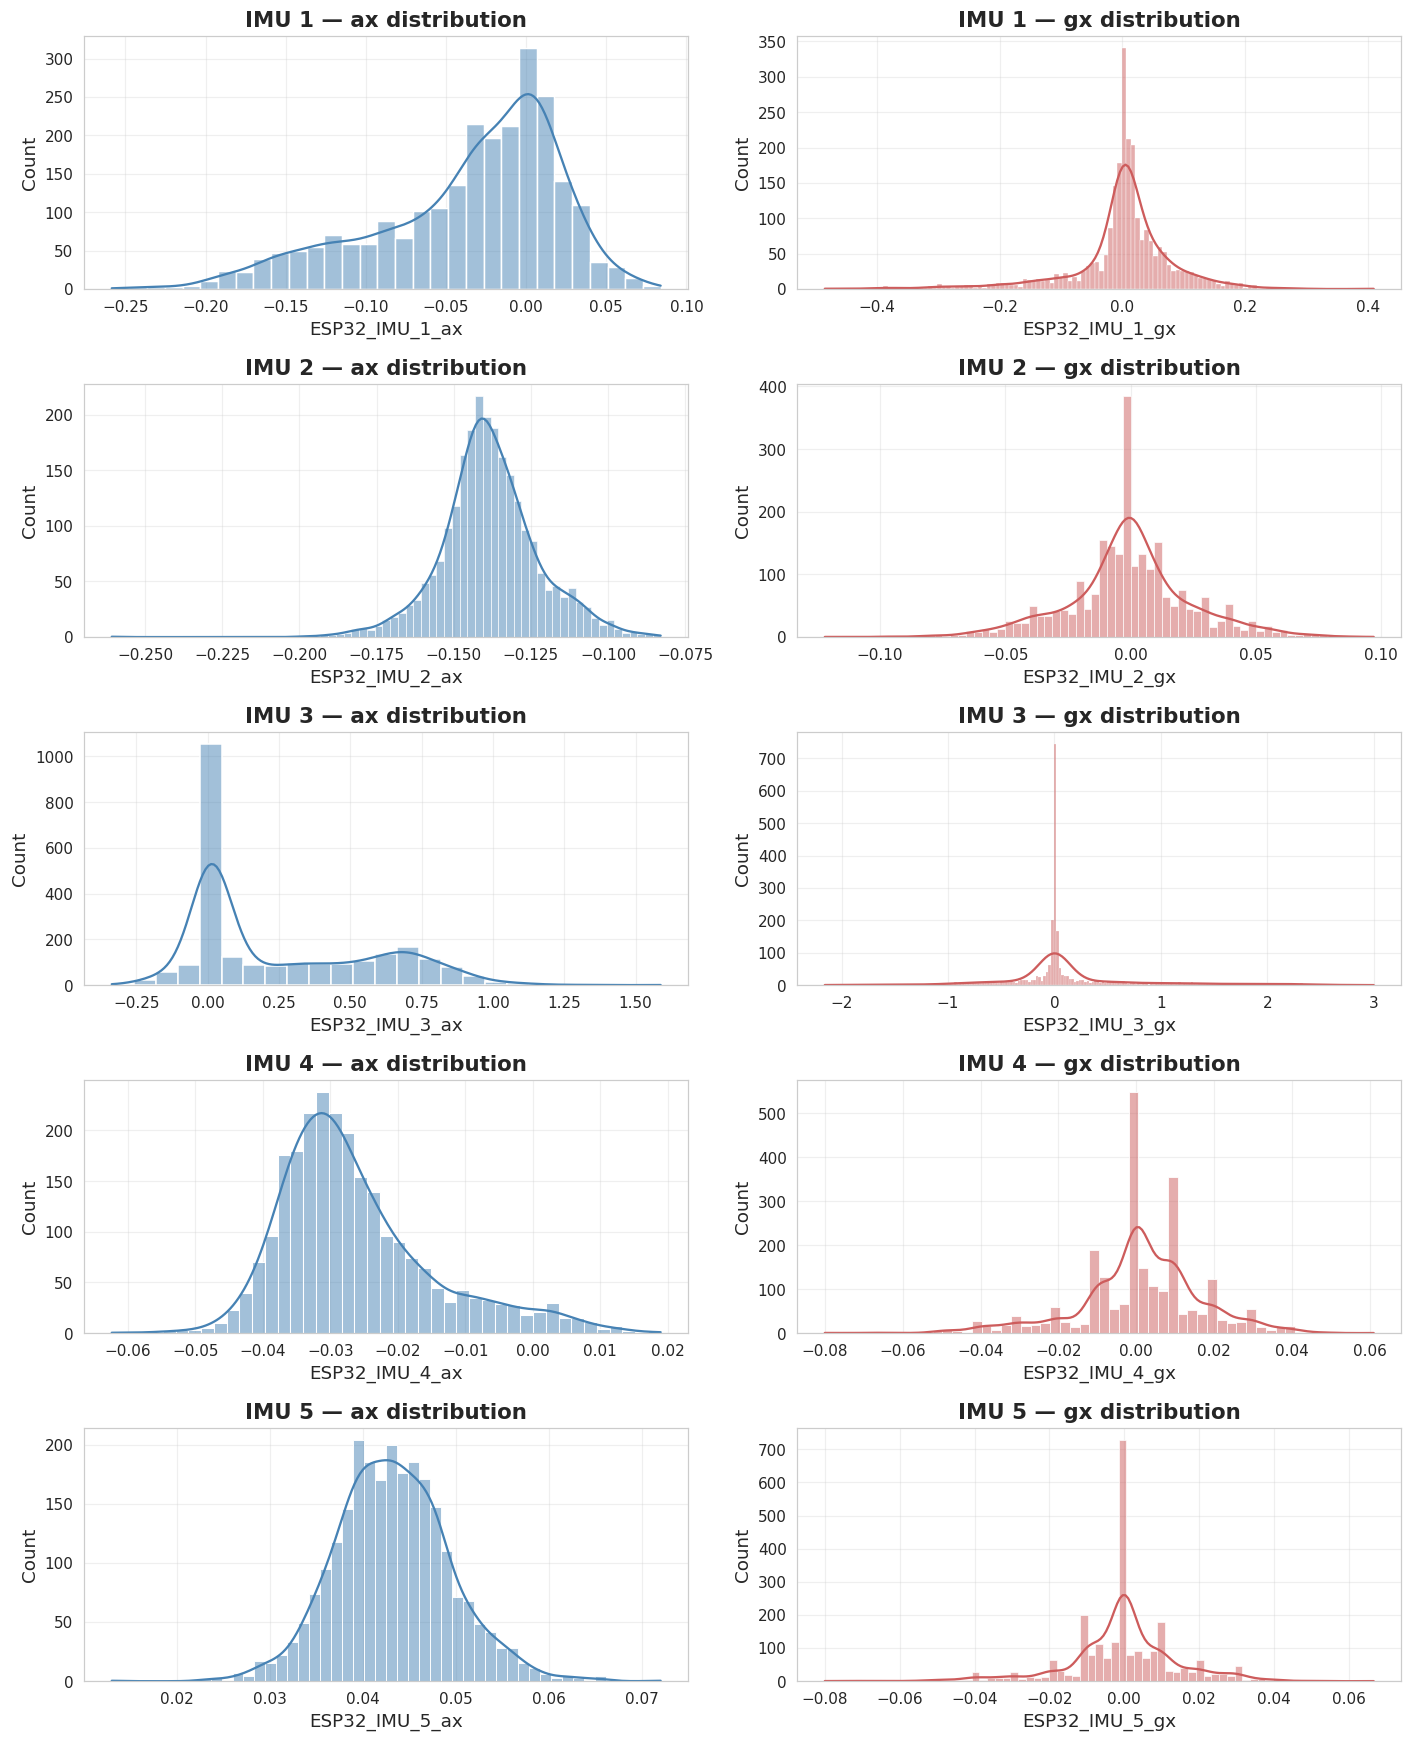

In [5]:
# Feature distributions — one accelerometer + one gyroscope channel per sensor
fig, axes = plt.subplots(5, 2, figsize=(13, 16))
for i in range(1, 6):
    sns.histplot(df[f"ESP32_IMU_{i}_ax"], kde=True, ax=axes[i-1, 0], color="steelblue")
    axes[i-1, 0].set_title(f"IMU {i} — ax distribution")
    sns.histplot(df[f"ESP32_IMU_{i}_gx"], kde=True, ax=axes[i-1, 1], color="indianred")
    axes[i-1, 1].set_title(f"IMU {i} — gx distribution")
plt.tight_layout()
savefig("eda_imu_feature_distributions.png")
plt.show()


Saved figure -> figures/eda_imu_correlation_heatmap.png


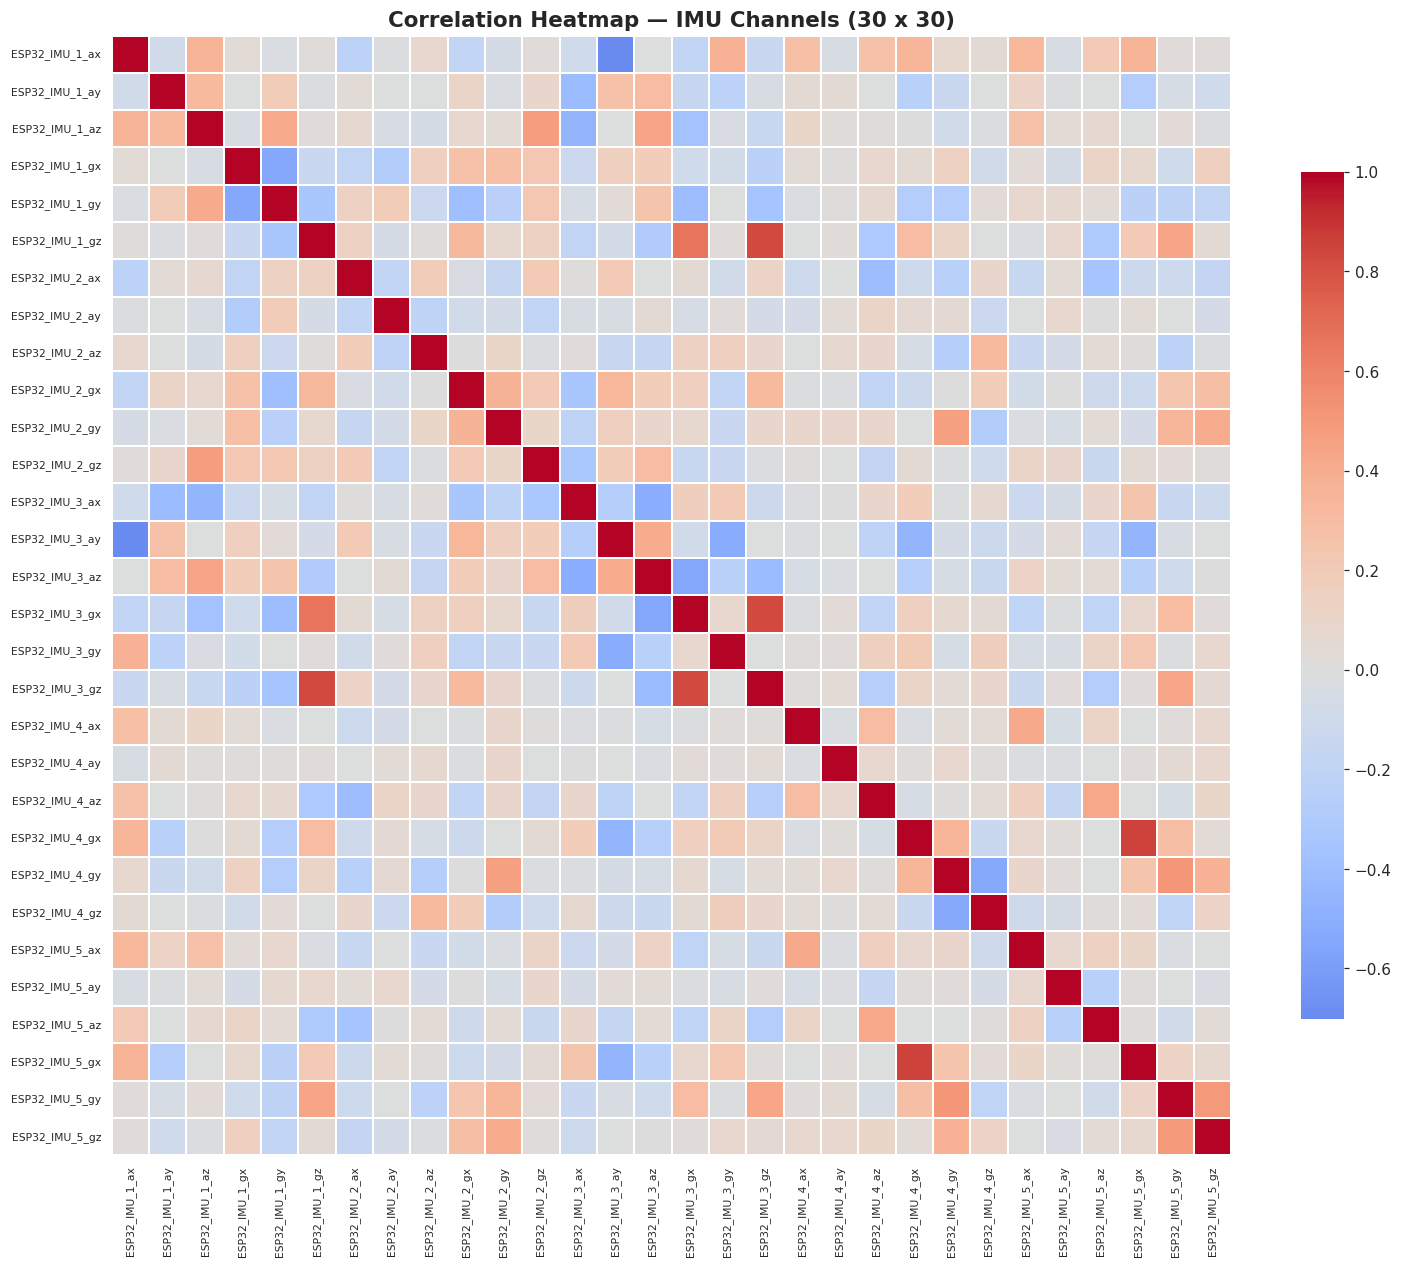

In [6]:
# Correlation heatmap across all 30 IMU channels
plt.figure(figsize=(14, 12))
corr = df[imu_cols].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.7})
plt.title("Correlation Heatmap — IMU Channels (30 x 30)")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
savefig("eda_imu_correlation_heatmap.png")
plt.show()


Saved figure -> figures/eda_imu_signal_traces.png


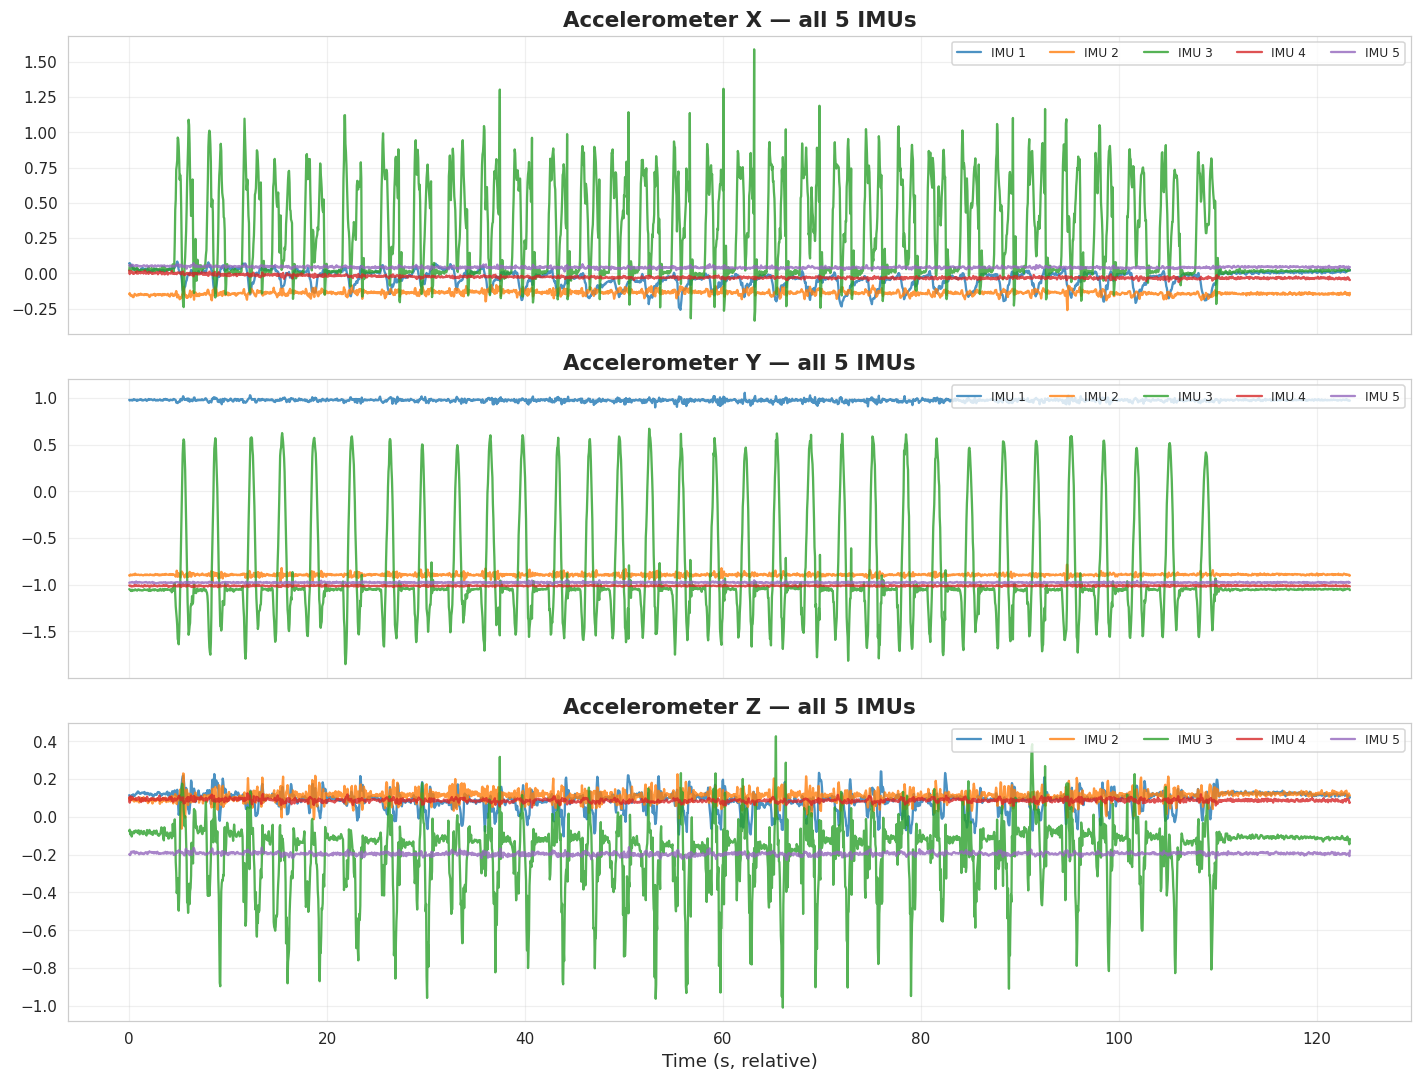

In [7]:
# Raw IMU signal traces over time (accelerometer, all 5 sensors)
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for i in range(1, 6):
    axes[0].plot(df["sys_time"] - df["sys_time"].iloc[0], df[f"ESP32_IMU_{i}_ax"], label=f"IMU {i}", alpha=0.8)
    axes[1].plot(df["sys_time"] - df["sys_time"].iloc[0], df[f"ESP32_IMU_{i}_ay"], label=f"IMU {i}", alpha=0.8)
    axes[2].plot(df["sys_time"] - df["sys_time"].iloc[0], df[f"ESP32_IMU_{i}_az"], label=f"IMU {i}", alpha=0.8)
axes[0].set_title("Accelerometer X — all 5 IMUs")
axes[1].set_title("Accelerometer Y — all 5 IMUs")
axes[2].set_title("Accelerometer Z — all 5 IMUs")
axes[2].set_xlabel("Time (s, relative)")
for ax in axes:
    ax.legend(loc="upper right", ncol=5, fontsize=8)
plt.tight_layout()
savefig("eda_imu_signal_traces.png")
plt.show()


Saved figure -> figures/eda_pose_trajectories.png


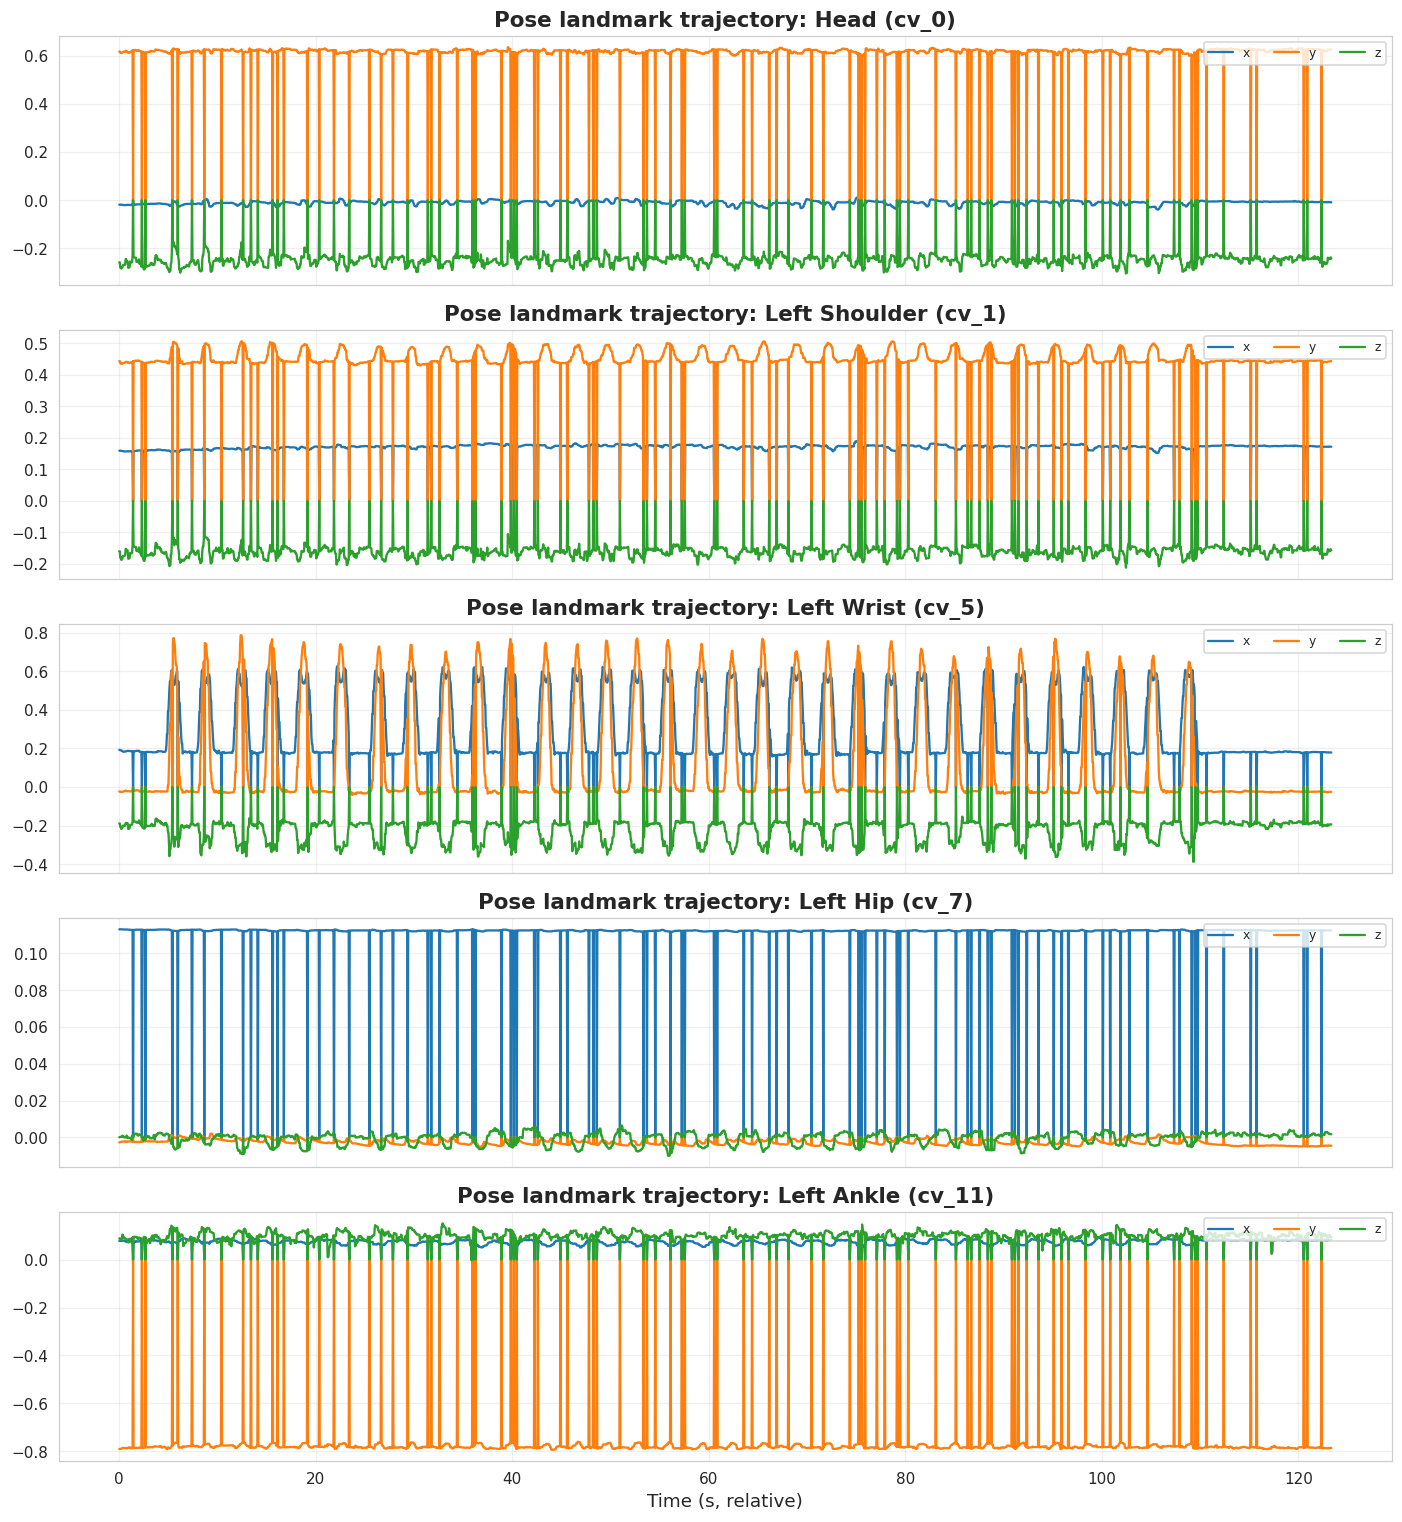

In [8]:
# Pose landmark trajectories over time: a handful of representative joints
sample_joints = [0, 1, 5, 7, 11]   # head, left shoulder, left wrist, left hip, left ankle (indices into KEYPOINT_NAMES)
fig, axes = plt.subplots(len(sample_joints), 1, figsize=(13, 14), sharex=True)
t = df["sys_time"] - df["sys_time"].iloc[0]
for ax, j in zip(axes, sample_joints):
    ax.plot(t, df[f"cv_{j}_x"], label="x")
    ax.plot(t, df[f"cv_{j}_y"], label="y")
    ax.plot(t, df[f"cv_{j}_z"], label="z")
    ax.set_title(f"Pose landmark trajectory: {KEYPOINT_NAMES[j]} (cv_{j})")
    ax.legend(loc="upper right", ncol=3, fontsize=8)
axes[-1].set_xlabel("Time (s, relative)")
plt.tight_layout()
savefig("eda_pose_trajectories.png")
plt.show()


Saved figure -> figures/eda_imu_boxplots.png


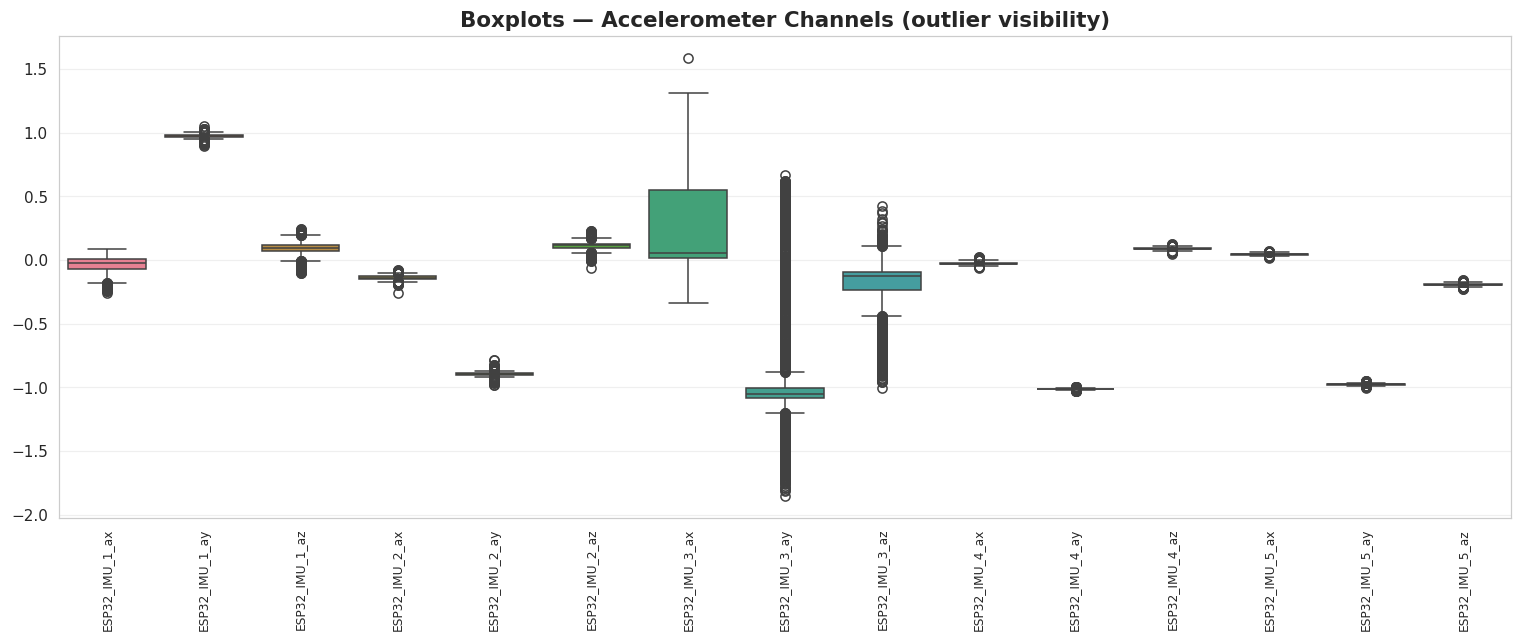

In [9]:
# Boxplots — outlier visibility across IMU accelerometer channels
plt.figure(figsize=(14, 6))
acc_cols = [c for c in imu_cols if c.endswith(("ax", "ay", "az"))]
sns.boxplot(data=df[acc_cols], orient="v")
plt.xticks(rotation=90, fontsize=8)
plt.title("Boxplots — Accelerometer Channels (outlier visibility)")
plt.tight_layout()
savefig("eda_imu_boxplots.png")
plt.show()


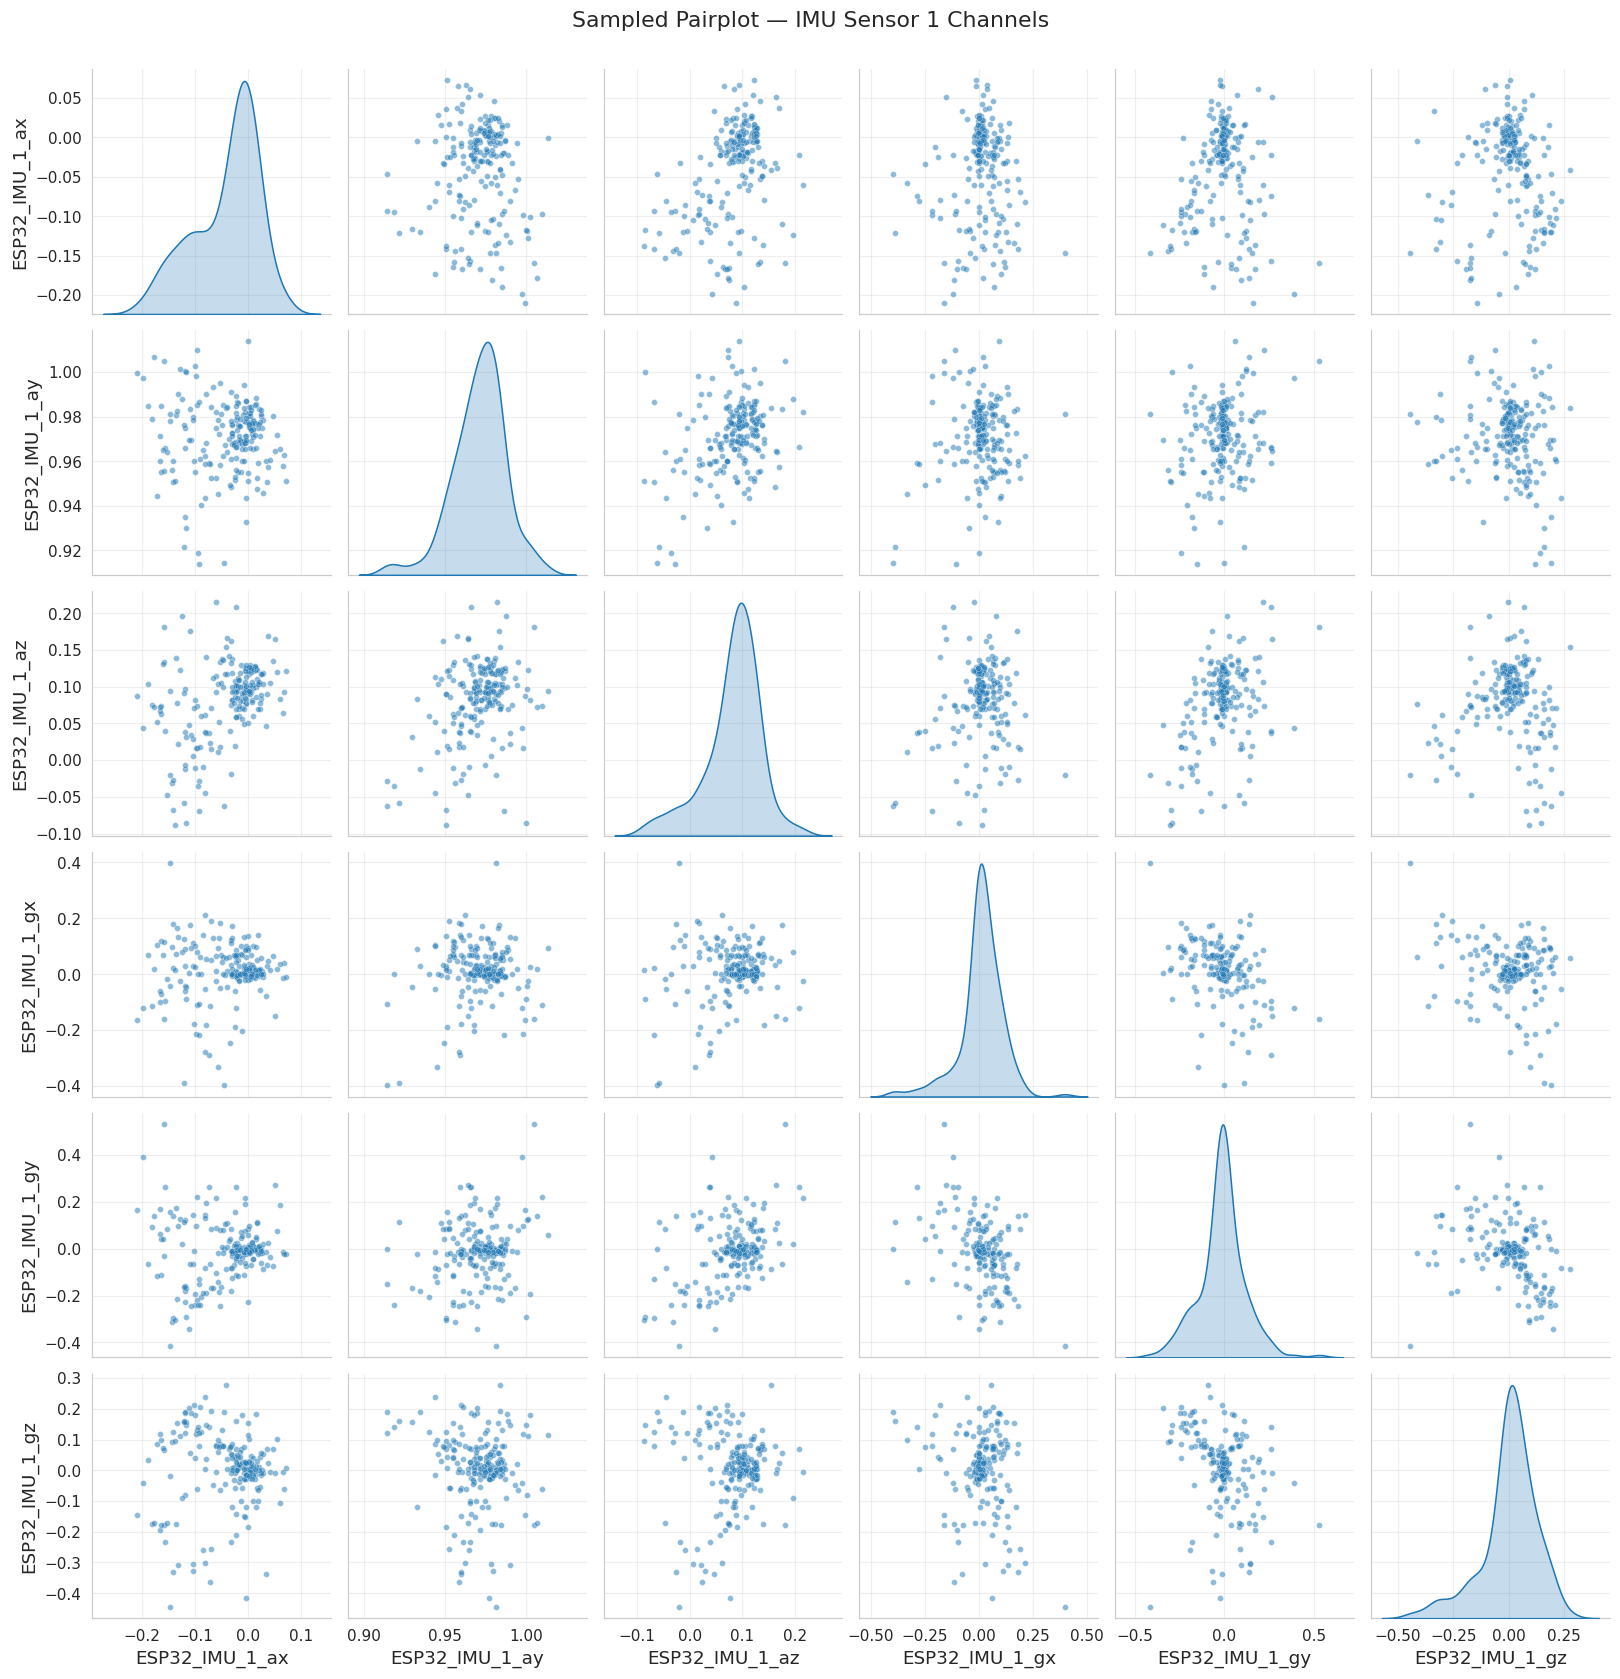

In [10]:
# Sampled pairplot — IMU_1 channels only (pairplots on all 30 features would be unreadable
# and extremely slow, so we sample rows AND restrict to one sensor's 6 channels)
sample_df = df.sample(n=min(200, len(df)), random_state=SEED)
sns.pairplot(sample_df[["ESP32_IMU_1_ax", "ESP32_IMU_1_ay", "ESP32_IMU_1_az",
                         "ESP32_IMU_1_gx", "ESP32_IMU_1_gy", "ESP32_IMU_1_gz"]],
             diag_kind="kde", plot_kws={"alpha": 0.5, "s": 15})
plt.suptitle("Sampled Pairplot — IMU Sensor 1 Channels", y=1.02)
plt.savefig(os.path.join(DIR_FIGURES, "eda_pairplot_imu1.png"), dpi=200, bbox_inches="tight")
plt.show()


Saved figure -> figures/eda_target_distributions.png


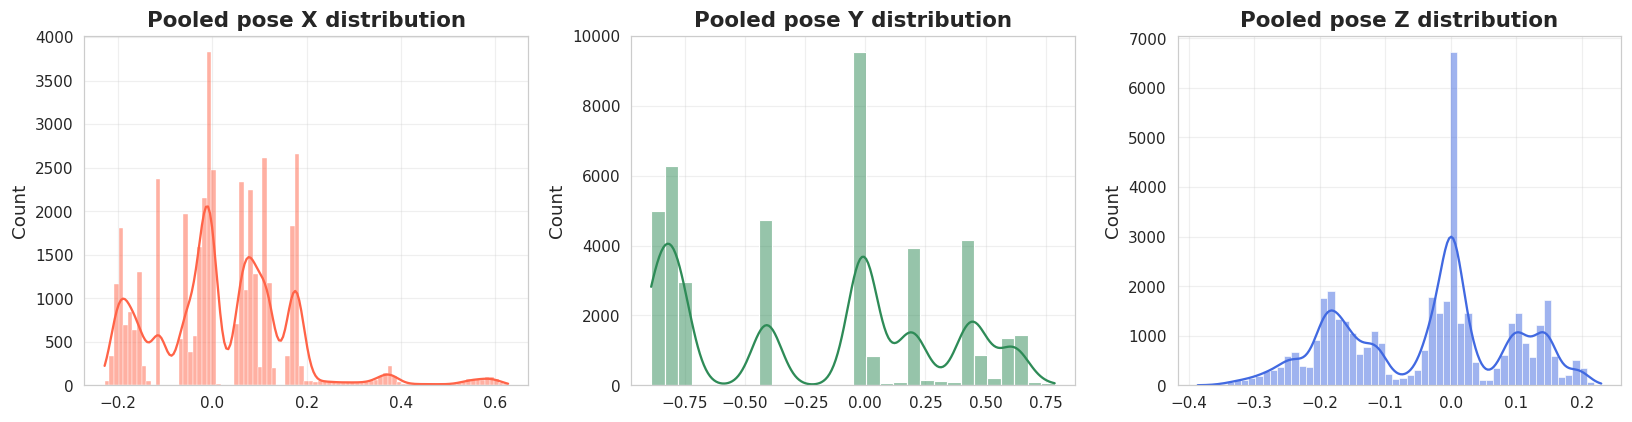

In [11]:
# Target (pose landmark) distributions — all x, all y, all z pooled together
x_vals = df[[c for c in pose_cols if c.endswith("_x")]].values.flatten()
y_vals = df[[c for c in pose_cols if c.endswith("_y")]].values.flatten()
z_vals = df[[c for c in pose_cols if c.endswith("_z")]].values.flatten()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(x_vals, kde=True, ax=axes[0], color="tomato"); axes[0].set_title("Pooled pose X distribution")
sns.histplot(y_vals, kde=True, ax=axes[1], color="seagreen"); axes[1].set_title("Pooled pose Y distribution")
sns.histplot(z_vals, kde=True, ax=axes[2], color="royalblue"); axes[2].set_title("Pooled pose Z distribution")
plt.tight_layout()
savefig("eda_target_distributions.png")
plt.show()


## 4. Data Cleaning

The checks below are written generically (they clean the data if problems are found). For this file there are 0 missing values and 0 duplicate rows (Section 2), but that does **not** prove the data is clean: a dropped IMU packet or a repeated camera frame is usually stored as a valid-looking number, not as NaN. The synchronisation and data-quality cells below look for those cases explicitly.


In [12]:
# Missing values: linear interpolation over numeric columns only (rows are evenly spaced in time)
if df.isnull().sum().sum() > 0:
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].interpolate(method="linear", limit_direction="both")
    print("Missing numeric values were interpolated linearly.")
else:
    print("No missing values found, nothing to interpolate.")

print("Missing values per column (only columns with >0 shown):")
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing if len(missing) else "None, dataset has zero missing values.")


Missing numeric values were interpolated linearly.
Missing values per column (only columns with >0 shown):
None, dataset has zero missing values.


In [13]:
# Outlier detection (report-only) via z-score on IMU channels.
# We do NOT drop outlier rows: this is a single continuous motion recording, and dropping
# rows would create artificial time gaps that break the sliding-window sequencing in Section 7.
z_scores = np.abs(stats.zscore(df[imu_cols]))
outlier_mask = (z_scores > 4).any(axis=1)
print(f"Rows with at least one IMU channel beyond |z|>4: {outlier_mask.sum()} / {len(df)}")
print("These are flagged for awareness only and retained, to preserve temporal continuity.")


Rows with at least one IMU channel beyond |z|>4: 131 / 2468
These are flagged for awareness only and retained, to preserve temporal continuity.


Mean frame interval: 50.00 ms  (~20.0 Hz)
Std of frame interval: 0.000 ms
Max frame interval: 50.00 ms
Saved figure -> figures/sync_check_dt.png


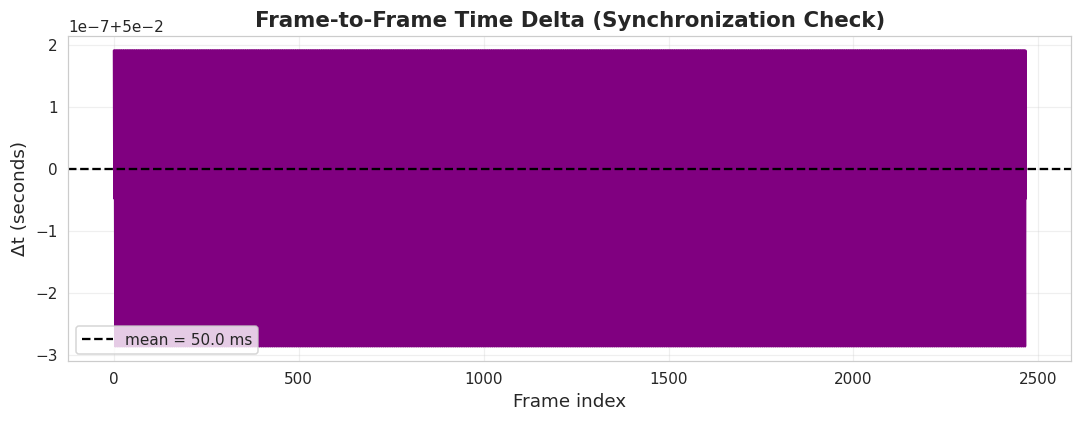

In [14]:
# Logging-rate check: the time delta between consecutive rows should be constant. This only shows
# that the logger's clock is regular. It does NOT prove that camera and IMU samples are aligned
# (see the alignment check in the next cell).
dt = df["sys_time"].diff().dropna()
approx_hz = 1.0 / dt.mean()
print(f"Mean frame interval: {dt.mean()*1000:.2f} ms  (~{approx_hz:.1f} Hz)")
print(f"Std of frame interval: {dt.std()*1000:.3f} ms")
print(f"Max frame interval: {dt.max()*1000:.2f} ms")

plt.figure(figsize=(10, 4))
plt.plot(dt.values, color="purple")
plt.axhline(dt.mean(), color="black", linestyle="--", label=f"mean = {dt.mean()*1000:.1f} ms")
plt.title("Frame-to-Frame Time Delta (Synchronization Check)")
plt.xlabel("Frame index")
plt.ylabel("Δt (seconds)")
plt.legend()
plt.tight_layout()
savefig("sync_check_dt.png")
plt.show()


Consecutive identical pose rows: 25.3%
IMU 1: all-zero rows = 0, rows identical to previous row = 0
IMU 2: all-zero rows = 0, rows identical to previous row = 0
IMU 3: all-zero rows = 0, rows identical to previous row = 0
IMU 4: all-zero rows = 0, rows identical to previous row = 2
IMU 5: all-zero rows = 0, rows identical to previous row = 0
Cross-correlation peak at lag 0 frames (0 ms), r = 0.056
Saved figure -> figures/sync_crosscorr.png


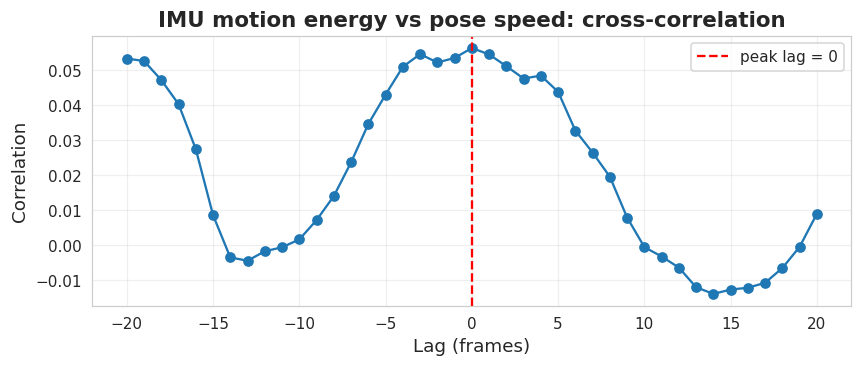

In [15]:
# Camera/IMU alignment and data-quality checks (report-only)

# 1) Repeated pose rows: a camera slower than the logger gives sample-and-hold pose labels.
pose_repeat = (df[pose_cols].diff().abs().sum(axis=1).iloc[1:] == 0).mean()
print(f"Consecutive identical pose rows: {pose_repeat:.1%}")

# 2) Possible dropped IMU packets: a sensor whose 6 channels are all zero, or unchanged vs. the previous row.
for s in range(1, 6):
    cols = [c for c in imu_cols if c.startswith(f"ESP32_IMU_{s}_")]
    block = df[cols]
    zero_rows  = int((block == 0).all(axis=1).sum())
    stuck_rows = int((block.diff().abs().sum(axis=1).iloc[1:] == 0).sum())
    print(f"IMU {s}: all-zero rows = {zero_rows}, rows identical to previous row = {stuck_rows}")

# 3) Estimated lag between IMU motion energy and pose speed (normalised cross-correlation).
#    lag > 0 means the IMU signal trails the camera by that many frames.
gyro_cols  = [c for c in imu_cols if c.endswith(("gx", "gy", "gz"))]
imu_energy = np.sqrt((df[gyro_cols] ** 2).sum(axis=1)).values
pose_speed = np.sqrt((df[pose_cols].diff().fillna(0) ** 2).sum(axis=1)).values
z = lambda a: (a - a.mean()) / (a.std() + 1e-9)
imu_energy, pose_speed = z(imu_energy), z(pose_speed)
N_ = len(imu_energy)
lags = np.arange(-20, 21)
xc = np.array([np.mean(imu_energy[max(0, l):N_ + min(0, l)] * pose_speed[max(0, -l):N_ + min(0, -l)]) for l in lags])
best_lag = int(lags[xc.argmax()])
print(f"Cross-correlation peak at lag {best_lag} frames ({best_lag * dt.mean() * 1000:.0f} ms), r = {xc.max():.3f}")
if abs(best_lag) >= 2:
    print("WARNING: IMU and camera look misaligned by 2+ frames. Shift one stream before windowing.")

plt.figure(figsize=(8, 3.5))
plt.plot(lags, xc, marker="o")
plt.axvline(best_lag, color="red", linestyle="--", label=f"peak lag = {best_lag}")
plt.xlabel("Lag (frames)"); plt.ylabel("Correlation")
plt.title("IMU motion energy vs pose speed: cross-correlation")
plt.legend(); plt.tight_layout()
savefig("sync_crosscorr.png")
plt.show()


## 5. Feature Engineering - Separating Inputs (X) and Targets (Y)

IMU and pose columns were already auto-detected in Section 3 using regular expressions
(robust to sensor/joint count changes). Here we materialize the final `X` (IMU) and
`Y` (pose) arrays, sorted by time.


In [16]:
df = df.sort_values("sys_time").reset_index(drop=True)

X_raw = df[imu_cols].values.astype("float32")   # shape: (n_frames, 30)
Y_raw = df[pose_cols].values.astype("float32")  # shape: (n_frames, 51)

print("X_raw (IMU) shape :", X_raw.shape)
print("Y_raw (pose) shape:", Y_raw.shape)
print("\nIMU columns (input order):")
print(imu_cols)
print("\nPose columns (output order):")
print(pose_cols)

X_raw (IMU) shape : (2468, 30)
Y_raw (pose) shape: (2468, 51)

IMU columns (input order):
['ESP32_IMU_1_ax', 'ESP32_IMU_1_ay', 'ESP32_IMU_1_az', 'ESP32_IMU_1_gx', 'ESP32_IMU_1_gy', 'ESP32_IMU_1_gz', 'ESP32_IMU_2_ax', 'ESP32_IMU_2_ay', 'ESP32_IMU_2_az', 'ESP32_IMU_2_gx', 'ESP32_IMU_2_gy', 'ESP32_IMU_2_gz', 'ESP32_IMU_3_ax', 'ESP32_IMU_3_ay', 'ESP32_IMU_3_az', 'ESP32_IMU_3_gx', 'ESP32_IMU_3_gy', 'ESP32_IMU_3_gz', 'ESP32_IMU_4_ax', 'ESP32_IMU_4_ay', 'ESP32_IMU_4_az', 'ESP32_IMU_4_gx', 'ESP32_IMU_4_gy', 'ESP32_IMU_4_gz', 'ESP32_IMU_5_ax', 'ESP32_IMU_5_ay', 'ESP32_IMU_5_az', 'ESP32_IMU_5_gx', 'ESP32_IMU_5_gy', 'ESP32_IMU_5_gz']

Pose columns (output order):
['cv_0_x', 'cv_0_y', 'cv_0_z', 'cv_1_x', 'cv_1_y', 'cv_1_z', 'cv_2_x', 'cv_2_y', 'cv_2_z', 'cv_3_x', 'cv_3_y', 'cv_3_z', 'cv_4_x', 'cv_4_y', 'cv_4_z', 'cv_5_x', 'cv_5_y', 'cv_5_z', 'cv_6_x', 'cv_6_y', 'cv_6_z', 'cv_7_x', 'cv_7_y', 'cv_7_z', 'cv_8_x', 'cv_8_y', 'cv_8_z', 'cv_9_x', 'cv_9_y', 'cv_9_z', 'cv_10_x', 'cv_10_y', 'cv_10_z', 'cv_1

## 6. Train / Validation / Test Split: block-wise with purge gaps

A single chronological cut (first 70% / next 20% / last 10%) puts different parts of the motion in train, val and test. That measures extrapolation to unseen motion and makes validation loss stop improving early. That is a distribution shift, not a patience problem.

**Default scheme (`SPLIT_MODE = "blocked"`).** The recording is cut into 12 contiguous blocks. Blocks 2 and 8 are validation, blocks 5 and 11 are test, the other 8 are training, so every split sees the whole range of the motion. A `GAP` of `WINDOW_SIZE` frames is trimmed from every val/test edge that touches another block, so no training window overlaps a val/test window, and windows are built *inside* each block so none straddles a boundary. Scalers are fit on training rows only.

Neighbouring frames are still strongly autocorrelated, so a blocked score measures **interpolation inside one recorded session**. Set `SPLIT_MODE = "chrono"` for the strict chronological split (val/test separated from train by the same `GAP`), which measures extrapolation to later motion. Report both in the thesis.


In [17]:
WINDOW_SIZE = 10      # ~0.5 s of history at the logged ~20 Hz
STRIDE      = 1
SPLIT_MODE  = "blocked"   # "blocked" (default) or "chrono"

N_BLOCKS    = 12
VAL_BLOCKS  = {2, 8}
TEST_BLOCKS = {5, 11}
GAP         = WINDOW_SIZE

n = len(df)
segments = []   # (split_name, start_row, end_row) -- contiguous row ranges

if SPLIT_MODE == "blocked":
    edges = np.linspace(0, n, N_BLOCKS + 1).astype(int)
    for i in range(N_BLOCKS):
        name = "val" if i in VAL_BLOCKS else "test" if i in TEST_BLOCKS else "train"
        s, e = int(edges[i]), int(edges[i + 1])
        if name != "train":                       # purge gap only on edges that touch another block
            if i > 0:             s += GAP
            if i < N_BLOCKS - 1:  e -= GAP
        segments.append((name, s, e))
elif SPLIT_MODE == "chrono":
    a, b = int(n * 0.70), int(n * 0.90)
    segments = [("train", 0, a), ("val", a + GAP, b), ("test", b + GAP, n)]
else:
    raise ValueError("SPLIT_MODE must be 'blocked' or 'chrono'")

# sanity checks: no row used twice, every segment can hold at least one window
_cover = np.zeros(n, dtype=int)
for _, s, e in segments:
    _cover[s:e] += 1
assert _cover.max() <= 1, "segments overlap"
assert all(e - s >= WINDOW_SIZE for _, s, e in segments), "a segment is shorter than WINDOW_SIZE"

for split in ("train", "val", "test"):
    rows = sum(e - s for nm, s, e in segments if nm == split)
    print(f"{split:5s}: {rows:5d} frames in {sum(nm == split for nm, _, _ in segments)} segment(s)")


train:  1644 frames in 8 segment(s)
val  :   372 frames in 2 segment(s)
test :   382 frames in 2 segment(s)


## 7. Normalization

In [18]:
train_rows = np.concatenate([np.arange(s, e) for nm, s, e in segments if nm == "train"])

imu_scaler  = StandardScaler().fit(X_raw[train_rows])
pose_scaler = StandardScaler().fit(Y_raw[train_rows])

X_scaled = imu_scaler.transform(X_raw).astype("float32")
Y_scaled = pose_scaler.transform(Y_raw).astype("float32")

joblib.dump(imu_scaler,  os.path.join(DIR_SCALERS, "imu_scaler.joblib"))
joblib.dump(pose_scaler, os.path.join(DIR_SCALERS, "pose_scaler.joblib"))
print("Scalers fit on TRAIN rows only, applied everywhere, and saved to disk.")


Scalers fit on TRAIN rows only, applied everywhere, and saved to disk.


## 8. Sliding-Window Sequence Construction

**Design choice:** each window of `WINDOW_SIZE` consecutive IMU frames is used to predict the pose landmarks at the **last frame of that window** (nowcasting the current pose from the trailing IMU history). This mirrors real-time deployment, where only past and current IMU samples are available, and avoids look-ahead leakage.

Windows are built **inside each contiguous segment**, so none crosses a split boundary. A short window (`WINDOW_SIZE = 10`, about 0.5 s) keeps the number of near-duplicate overlapping training samples low.


In [19]:
def create_sequences(X, Y, window_size=WINDOW_SIZE, stride=STRIDE):
    """Overlapping windows from ONE contiguous segment. Target = pose at the LAST frame."""
    if len(X) < window_size:
        return np.empty((0, window_size, X.shape[1]), "float32"), np.empty((0, Y.shape[1]), "float32")
    xs, ys = [], []
    for start in range(0, len(X) - window_size + 1, stride):
        end = start + window_size
        xs.append(X[start:end]); ys.append(Y[end - 1])
    return np.array(xs, dtype="float32"), np.array(ys, dtype="float32")

parts = {"train": ([], []), "val": ([], []), "test": ([], [])}
seg_windows = {"train": [], "val": [], "test": []}     # windows per segment (used to mark block seams in plots)
for name, s, e in segments:
    xs, ys = create_sequences(X_scaled[s:e], Y_scaled[s:e])
    parts[name][0].append(xs); parts[name][1].append(ys)
    seg_windows[name].append(len(xs))

X_train, Y_train = (np.concatenate(p) for p in parts["train"])
X_val,   Y_val   = (np.concatenate(p) for p in parts["val"])
X_test,  Y_test  = (np.concatenate(p) for p in parts["test"])
TEST_SEAMS = np.cumsum(seg_windows["test"])[:-1]       # indices in the test set where one test block ends

print(f"X_train {X_train.shape}  Y_train {Y_train.shape}")
print(f"X_val   {X_val.shape}  Y_val   {Y_val.shape}")
print(f"X_test  {X_test.shape}  Y_test  {Y_test.shape}")

N_FEATURES = X_train.shape[-1]
N_OUTPUTS  = Y_train.shape[-1]
assert not np.isnan(X_train).any() and not np.isnan(Y_train).any(), "NaNs left in the data"


X_train (1572, 10, 30)  Y_train (1572, 51)
X_val   (354, 10, 30)  Y_val   (354, 51)
X_test  (364, 10, 30)  Y_test  (364, 51)


## 9. Model Architectures (small and regularised)

Five models sized for roughly 2k training windows:

| # | Model | Design |
|---|-------|--------|
| 1 | MLP | 128-64 units, dropout, L2 |
| 2 | 1D-CNN | causal convs 32/64, spatial dropout, last-step + average pooling |
| 3 | GRU | single 64-unit layer + skip path from the latest IMU frame |
| 4 | LSTM | single 64-unit layer + skip path from the latest IMU frame |
| 5 | Transformer | d_model 32, 2 heads, 1 block, last-step + average pooling |

Why a skip path / last-step: the latest IMU frame already carries most of the information about the current posture (compare the last-frame ExtraTrees reference in Section 11.1), so the recurrent or attention part only has to learn a correction from motion history.

Regularisation active **only during training**: Gaussian input noise and random *sensor dropout* (blanks all 6 channels of one sensor, i.e. sets them to the train mean after standardisation). This is a robustness augmentation for dropped packets. A real dropped packet may be logged as raw zeros, which is not the same as the standardised zero used here, so check how your logger encodes a drop (see the data-quality cell in Section 4). Output layers are float32.


In [20]:
L2 = keras.regularizers.l2(1e-4)
NOISE_STD      = 0.10   # Gaussian noise on standardised inputs (training only)
SENSOR_DROPOUT = 0.05   # probability of blanking one whole sensor per sample (training only)


@keras.utils.register_keras_serializable(package="mocap")
class SensorDropout(layers.Layer):
    """Training-only: independently blank each sensor's channels (set to the train mean = 0)."""
    def __init__(self, n_sensors, channels=6, rate=0.05, **kwargs):
        super().__init__(**kwargs)
        self.n_sensors, self.channels, self.rate = n_sensors, channels, rate

    def call(self, x, training=None):
        if not training or self.rate <= 0:
            return x
        shape = tf.shape(x)
        x5 = tf.reshape(x, (shape[0], shape[1], self.n_sensors, self.channels))
        keep = tf.cast(tf.random.uniform((shape[0], 1, self.n_sensors, 1)) >= self.rate, x.dtype)
        return tf.reshape(x5 * keep, shape)

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config()
        cfg.update(n_sensors=self.n_sensors, channels=self.channels, rate=self.rate)
        return cfg


def _inputs(window_size, n_features):
    inp = layers.Input(shape=(window_size, n_features), name="imu_window")
    x = SensorDropout(n_features // 6, 6, SENSOR_DROPOUT)(inp)
    x = layers.GaussianNoise(NOISE_STD)(x)
    return inp, x


def last_step(x):
    """Features of the most recent time step -> (batch, features)."""
    return layers.Flatten()(layers.Cropping1D((x.shape[1] - 1, 0))(x))


def build_mlp(window_size, n_features, n_outputs):
    inp, x = _inputs(window_size, n_features)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="MLP")


def build_cnn1d(window_size, n_features, n_outputs):
    inp, x = _inputs(window_size, n_features)
    x = layers.Conv1D(32, 3, padding="causal", activation="relu", kernel_regularizer=L2)(x)
    x = layers.Conv1D(64, 3, padding="causal", activation="relu", kernel_regularizer=L2)(x)
    x = layers.SpatialDropout1D(0.2)(x)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), last_step(x)])
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="CNN1D")


def _recurrent(cell_layer, name):
    def build(window_size, n_features, n_outputs):
        inp, x = _inputs(window_size, n_features)
        r = cell_layer(64)(x)
        r = layers.Dropout(0.3)(r)
        s = layers.Dense(32, activation="relu", kernel_regularizer=L2)(last_step(x))  # skip path
        h = layers.Concatenate()([r, s])
        h = layers.Dense(64, activation="relu", kernel_regularizer=L2)(h)
        h = layers.Dropout(0.2)(h)
        out = layers.Dense(n_outputs, name="pose_output")(h)
        return keras.Model(inp, out, name=name)
    return build

build_gru  = _recurrent(layers.GRU,  "GRU")
build_lstm = _recurrent(layers.LSTM, "LSTM")


@keras.utils.register_keras_serializable(package="mocap")
class PositionalEncoding(layers.Layer):
    def __init__(self, seq_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.seq_len, self.d_model = seq_len, d_model
        pos = np.arange(seq_len)[:, None]
        i = np.arange(d_model)[None, :]
        angle_rads = pos * (1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model)))
        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
        self.pos_encoding = tf.constant(angle_rads[None, ...], dtype=tf.float32)

    def call(self, x):
        return x + tf.cast(self.pos_encoding, x.dtype)

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config()
        cfg.update(seq_len=self.seq_len, d_model=self.d_model)
        return cfg


def transformer_encoder_block(x, d_model, num_heads, ff_dim, dropout=0.2):
    attn = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)(x, x)
    attn = layers.Dropout(dropout)(attn)
    x = layers.LayerNormalization(epsilon=1e-6)(x + attn)
    ffn = layers.Dense(ff_dim, activation="relu", kernel_regularizer=L2)(x)
    ffn = layers.Dense(d_model, kernel_regularizer=L2)(ffn)
    ffn = layers.Dropout(dropout)(ffn)
    return layers.LayerNormalization(epsilon=1e-6)(x + ffn)


def build_transformer(window_size, n_features, n_outputs,
                      d_model=32, num_heads=2, ff_dim=64, num_blocks=1, dropout=0.2):
    inp, x = _inputs(window_size, n_features)
    x = layers.Dense(d_model)(x)
    x = PositionalEncoding(window_size, d_model)(x)
    for _ in range(num_blocks):
        x = transformer_encoder_block(x, d_model, num_heads, ff_dim, dropout)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), last_step(x)])
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="Transformer")


MODEL_BUILDERS = {
    "MLP":         build_mlp,
    "CNN1D":       build_cnn1d,
    "GRU":         build_gru,
    "LSTM":        build_lstm,
    "Transformer": build_transformer,
}

for name, builder in MODEL_BUILDERS.items():
    m = builder(WINDOW_SIZE, N_FEATURES, N_OUTPUTS)
    print(f"{name:12s} -> {m.count_params():,} parameters")
    del m


I0000 00:00:1792571951.650784      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792571951.654306      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


MLP          -> 50,099 parameters
CNN1D        -> 20,691 parameters
GRU          -> 28,947 parameters
LSTM         -> 34,835 parameters
Transformer  -> 17,011 parameters


## 10. Training

Same optimiser, loss and callbacks for every model.

* **Weighted Huber loss.** Per-column standardisation would give almost-static columns (legs, torso) the same weight as the moving left arm. Each column is therefore weighted by its original-unit variance share, with a floor (`LOSS_FLOOR`) so none is ignored. This makes the loss roughly follow original-unit error, which is what MPJPE measures. Huber makes it robust to MediaPipe jitter.
* **AdamW** (weight decay), **batch 64**, `lr = 1e-3` with `ReduceLROnPlateau`.
* **`EarlyStopping(patience=40, min_delta=1e-4)`** on validation loss with best-weight restore.
* **Seed ensemble** (`N_SEEDS` models averaged) to reduce run-to-run variance. Parameter counts reported later are per member; FPS is for the whole ensemble.
* The logged training loss includes input noise, dropout and L2, while validation loss does not, so the printed val/train ratio is **not** a clean over-fitting measure. Use the Test/Train MPJPE table in Section 11.1 (both evaluated in inference mode).


In [21]:
EPOCHS     = 300      # upper bound; EarlyStopping decides
BATCH_SIZE = 64
N_SEEDS    = 3
LOSS_FLOOR = 0.25     # minimum relative weight of a (near-)static column

# ---- loss weights: variance share per column (original units), floored, mean = 1 ----
s2 = pose_scaler.scale_ ** 2
w = LOSS_FLOOR + (1 - LOSS_FLOOR) * (s2 / s2.mean())
LOSS_W = tf.constant(w / w.mean(), dtype=tf.float32)

def weighted_huber(y_true, y_pred, delta=1.0):
    err  = tf.abs(y_pred - y_true)
    quad = tf.minimum(err, delta)
    lin  = err - quad
    return tf.reduce_mean(LOSS_W * (0.5 * quad ** 2 + delta * lin), axis=-1)


class EnsembleModel:
    """Averages several Keras models. Exposes the small API the rest of the notebook uses."""
    def __init__(self, members):
        self.members = members

    def predict(self, X, verbose=0, **kwargs):
        preds = [np.asarray(m.predict(X, verbose=0, **kwargs), dtype="float64") for m in self.members]
        return np.mean(preds, axis=0)

    def count_params(self):              # parameters of ONE member (the ensemble has N_SEEDS of them)
        return int(self.members[0].count_params())

    @classmethod
    def load(cls, path):
        """Inverse of save(): loads <stem>_member*.keras into an ensemble."""
        import glob
        stem = path[:-6] if path.endswith(".keras") else path
        files = sorted(glob.glob(f"{stem}_member*.keras"))
        if not files:
            raise FileNotFoundError(f"No ensemble members found for {stem}_member*.keras")
        return cls([keras.models.load_model(f, compile=False) for f in files])

    def save(self, path):
        stem = path[:-6] if path.endswith(".keras") else path
        for i, m in enumerate(self.members):
            m.save(f"{stem}_member{i}.keras")


histories, trained_models, training_times = {}, {}, {}

for name, builder in MODEL_BUILDERS.items():
    print("\n" + "=" * 70)
    print(f"Training {name}  ({N_SEEDS} seeds)")
    print("=" * 70)

    members, start = [], time.time()
    for k in range(N_SEEDS):
        seed = SEED + k
        tf.keras.backend.clear_session()
        keras.utils.set_random_seed(seed)

        model = builder(WINDOW_SIZE, N_FEATURES, N_OUTPUTS)
        model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-3),
                      loss=weighted_huber, metrics=["mae"])

        ckpt_path = os.path.join(DIR_MODELS, f"{name}_seed{k}_best.keras")
        callbacks = [
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, min_delta=1e-4,
                                          restore_best_weights=True, verbose=0),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=12,
                                              min_lr=1e-5, verbose=0),
            keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True, verbose=0),
            keras.callbacks.TensorBoard(log_dir=os.path.join(DIR_LOGS, f"{name}_seed{k}")),
        ]
        hist = model.fit(X_train, Y_train, validation_data=(X_val, Y_val),
                         epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=0)

        h = hist.history
        best = int(np.argmin(h["val_loss"]))
        print(f"  seed {k}: {len(h['loss']):3d} epochs | best epoch {best + 1:3d} | "
              f"train loss {h['loss'][best]:.4f} | val loss {h['val_loss'][best]:.4f} "
              f"(val/train x{h['val_loss'][best] / max(h['loss'][best], 1e-9):.2f})")
        members.append(model)
        if k == 0:
            histories[name] = h        # seed-0 curves are used for the plots

    elapsed = time.time() - start
    trained_models[name] = EnsembleModel(members)
    training_times[name] = elapsed
    print(f"{name}: total training time {elapsed:.1f} s")

with open(os.path.join(DIR_RESULTS, "training_history.json"), "w") as f:
    json.dump(histories, f, indent=2)
print("\nTraining histories (seed 0) saved to results/training_history.json")



Training MLP  (3 seeds)


I0000 00:00:1792571958.765030     132 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  seed 0:  96 epochs | best epoch  73 | train loss 0.1094 | val loss 0.1666 (val/train x1.52)
  seed 1:  75 epochs | best epoch  35 | train loss 0.1690 | val loss 0.1663 (val/train x0.98)
  seed 2:  81 epochs | best epoch  42 | train loss 0.1628 | val loss 0.1660 (val/train x1.02)
MLP: total training time 76.6 s

Training CNN1D  (3 seeds)
  seed 0:  74 epochs | best epoch  34 | train loss 0.1532 | val loss 0.1564 (val/train x1.02)
  seed 1:  83 epochs | best epoch  43 | train loss 0.1512 | val loss 0.1547 (val/train x1.02)
  seed 2:  73 epochs | best epoch  33 | train loss 0.1546 | val loss 0.1579 (val/train x1.02)
CNN1D: total training time 75.5 s

Training GRU  (3 seeds)
  seed 0:  87 epochs | best epoch  47 | train loss 0.1474 | val loss 0.1532 (val/train x1.04)
  seed 1:  87 epochs | best epoch  47 | train loss 0.1468 | val loss 0.1525 (val/train x1.04)
  seed 2:  84 epochs | best epoch  44 | train loss 0.1474 | val loss 0.1529 (val/train x1.04)
GRU: total training time 93.0 s

Tra

## 11. Evaluation

For each model we compute **MAE, MSE, RMSE** and **MPJPE** (Mean Per Joint Position Error, the average 3D Euclidean distance between predicted and true joints, the standard pose-estimation metric) on inverse-scaled, original-unit predictions. We also record parameter count (per ensemble member), training time, pure `predict` time and inference FPS (whole ensemble, batch prediction).

**Model selection uses validation MPJPE only.** The test set is reported, never used to pick the best model.

**R² for multi-output pose regression.** The default uniform R² averages 51 per-column scores, each divided by that column's own variance. Near-static columns (hips, knees) have a tiny denominator, so ordinary errors give a low score and these columns dominate the average. We report:

| Metric | Definition | Reading |
|---|---|---|
| `R2` | variance-weighted: 1 - sum(SSE) / sum(SST) | static columns get almost no weight |
| `R2 OOS` | 1 - SSE(model) / SSE(constant train mean) | > 0 means the model beats the train-mean benchmark |
| `R2 active` | uniform R² over columns whose **train** variance is at least `ACTIVE_VAR_FRAC` x the mean column variance | fixed column set, same for every split and model |
| `R2 uniform` | plain uniform average | reference only, do not rank models with it |

**Note on the split.** With `SPLIT_MODE = "blocked"` the test set is two separate blocks, so line plots of consecutive test frames show one seam (marked with a dotted line).


In [22]:
N_JOINTS = 17  # 51 outputs = 17 joints x 3 (x, y, z)

def mpjpe(y_true, y_pred, n_joints=N_JOINTS):
    """Mean Per Joint Position Error, averaged over all joints and samples."""
    yt = y_true.reshape(-1, n_joints, 3)
    yp = y_pred.reshape(-1, n_joints, 3)
    per_joint_dist = np.linalg.norm(yt - yp, axis=-1)   # (n_samples, n_joints)
    return per_joint_dist.mean(), per_joint_dist.mean(axis=0)  # overall, and per-joint


# ---------------------------------------------------------------------------------
# R2 for multi-output pose regression
# ---------------------------------------------------------------------------------
#   r2          variance-weighted: 1 - sum(SSE) / sum(SST), SST taken around the test mean
#   r2_oos      out-of-sample R2 vs a constant TRAIN-mean forecast (Campbell-Thompson)
#   r2_active   uniform R2 over columns that carry real motion in TRAIN
#               (variance >= ACTIVE_VAR_FRAC x mean column variance). Fixed set for all splits/models.
#   r2_uniform  plain uniform average, reference only
ACTIVE_VAR_FRAC = 0.10
ACTIVE_MASK = pose_scaler.var_ >= ACTIVE_VAR_FRAC * pose_scaler.var_.mean()

def r2_time_series(y_true, y_pred, train_mean, active_mask=ACTIVE_MASK):
    sse   = ((y_true - y_pred) ** 2).sum(axis=0)          # per column
    sse_b = ((y_true - train_mean) ** 2).sum(axis=0)      # benchmark: constant train mean
    return dict(
        r2         = r2_score(y_true, y_pred, multioutput="variance_weighted"),
        r2_oos     = 1.0 - sse.sum() / sse_b.sum(),
        r2_active  = r2_score(y_true[:, active_mask], y_pred[:, active_mask]),
        r2_uniform = r2_score(y_true, y_pred, multioutput="uniform_average"),
        n_active   = int(active_mask.sum()),
    )


def evaluate_split(model, X, Y_scaled_true):
    Y_pred_scaled = np.asarray(model.predict(X, verbose=0), dtype="float64")   # float64 for metric accuracy
    y_true = pose_scaler.inverse_transform(Y_scaled_true).astype("float64")
    y_pred = pose_scaler.inverse_transform(Y_pred_scaled).astype("float64")

    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2m  = r2_time_series(y_true, y_pred, pose_scaler.mean_)
    overall_mpjpe, per_joint_mpjpe = mpjpe(y_true, y_pred)
    return dict(mae=mae, mse=mse, rmse=rmse, mpjpe=overall_mpjpe,
                per_joint_mpjpe=per_joint_mpjpe, y_true=y_true, y_pred=y_pred, **r2m)


results = {}
for name, model in trained_models.items():
    train_metrics = evaluate_split(model, X_train, Y_train)
    val_metrics   = evaluate_split(model, X_val,   Y_val)

    test_metrics = evaluate_split(model, X_test, Y_test)

    # Pure inference timing: model.predict only (no metrics), after a warm-up, median of 5 runs
    model.predict(X_test[:64], verbose=0)
    runs = []
    for _ in range(5):
        t0 = time.perf_counter(); model.predict(X_test, verbose=0); runs.append(time.perf_counter() - t0)
    inference_time = float(np.median(runs))
    fps = len(X_test) / inference_time

    n_params = model.count_params()

    results[name] = dict(
        train=train_metrics, val=val_metrics, test=test_metrics,
        n_params=n_params, training_time=training_times[name],
        inference_time=inference_time, fps=fps,
    )

    print(f"\n{name}")
    print(f"  Params (per member)    : {n_params:,}")
    print(f"  Training time (s)      : {training_times[name]:.2f}")
    print(f"  Test  MAE / RMSE       : {test_metrics['mae']:.4f} / {test_metrics['rmse']:.4f}")
    print(f"  Test  MPJPE            : {test_metrics['mpjpe']:.4f}")
    print(f"  Test  R2 (var-weighted): {test_metrics['r2']:.4f}")
    print(f"  Test  R2 OOS vs train-mean: {test_metrics['r2_oos']:.4f}")
    print(f"  Test  R2 active cols ({test_metrics['n_active']}/{N_OUTPUTS}): {test_metrics['r2_active']:.4f}")
    print(f"  Test  R2 uniform (legacy): {test_metrics['r2_uniform']:.4f}")
    print(f"  Inference FPS (ensemble, batch): {fps:.1f}")

# Model selection uses VALIDATION MPJPE only. The test set is reported, never used to choose.
best_name = best_model_name = min(results, key=lambda k: results[k]["val"]["mpjpe"])
print(f"\nBest model by validation MPJPE: {best_name}")



MLP
  Params (per member)    : 50,099
  Training time (s)      : 76.59
  Test  MAE / RMSE       : 0.0137 / 0.0643
  Test  MPJPE            : 0.0307
  Test  R2 (var-weighted): 0.3160
  Test  R2 OOS vs train-mean: 0.3420
  Test  R2 active cols (29/51): 0.2193
  Test  R2 uniform (legacy): 0.2335
  Inference FPS (ensemble, batch): 1191.5

CNN1D
  Params (per member)    : 20,691
  Training time (s)      : 75.48
  Test  MAE / RMSE       : 0.0140 / 0.0642
  Test  MPJPE            : 0.0313
  Test  R2 (var-weighted): 0.3179
  Test  R2 OOS vs train-mean: 0.3439
  Test  R2 active cols (29/51): 0.2200
  Test  R2 uniform (legacy): 0.2398
  Inference FPS (ensemble, batch): 1182.3

GRU
  Params (per member)    : 28,947
  Training time (s)      : 93.01
  Test  MAE / RMSE       : 0.0138 / 0.0643
  Test  MPJPE            : 0.0309
  Test  R2 (var-weighted): 0.3158
  Test  R2 OOS vs train-mean: 0.3418
  Test  R2 active cols (29/51): 0.2186
  Test  R2 uniform (legacy): 0.2477
  Inference FPS (ensemble, ba

### 11.1 Reference baselines and over-fitting check

Ridge / ExtraTrees on the latest IMU frame only. If a deep model cannot beat these, extra capacity is not helping. `Test/Train` far above 1 means over-fitting.


In [23]:
# ---------------------------------------------------------------------------------
# Reference baselines + over-fitting check
# ---------------------------------------------------------------------------------
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor

class LastFrameSklearn:
    """Classical model that only sees the LATEST IMU frame of each window."""
    def __init__(self, est): self.est = est
    def fit(self, X, Y): self.est.fit(X[:, -1, :], Y); return self
    def predict(self, X, verbose=0): return self.est.predict(X[:, -1, :])

ref_models = {
    "Ridge (last frame)":      LastFrameSklearn(Ridge(alpha=10)),
    "ExtraTrees (last frame)": LastFrameSklearn(ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED)),
}

rows = []
for name, m in ref_models.items():
    m.fit(X_train, Y_train)
    tr, va, te = (evaluate_split(m, X_, Y_) for X_, Y_ in ((X_train, Y_train), (X_val, Y_val), (X_test, Y_test)))
    rows.append(dict(Model=name, Type="reference", TrainMPJPE=tr["mpjpe"], ValMPJPE=va["mpjpe"],
                     TestMPJPE=te["mpjpe"], TestR2_OOS=te["r2_oos"]))
for name, r in results.items():
    rows.append(dict(Model=name, Type="deep", TrainMPJPE=r["train"]["mpjpe"], ValMPJPE=r["val"]["mpjpe"],
                     TestMPJPE=r["test"]["mpjpe"], TestR2_OOS=r["test"]["r2_oos"]))

ref_df = pd.DataFrame(rows)
ref_df["Test/Train"] = ref_df["TestMPJPE"] / ref_df["TrainMPJPE"]       # >> 1  means over-fitting
ref_df = ref_df.sort_values("TestMPJPE").reset_index(drop=True)
ref_df.to_csv(os.path.join(DIR_RESULTS, "reference_vs_deep.csv"), index=False)
display(ref_df.round(5))
print(f"Split mode: {SPLIT_MODE}. Constant train-mean baseline MPJPE on test = "
      f"{mpjpe(pose_scaler.inverse_transform(Y_test), np.tile(pose_scaler.mean_, (len(Y_test), 1)))[0]:.5f}")


,Model,Type,TrainMPJPE,ValMPJPE,TestMPJPE,TestR2_OOS,Test/Train
0,MLP,deep,0.02921,0.03551,0.03067,0.34200,1.05013
1,Transformer,deep,0.03256,0.03510,0.03080,0.34236,0.94607
2,LSTM,deep,0.03288,0.03575,0.03093,0.34343,0.94069
3,GRU,deep,0.03293,0.03586,0.03094,0.34180,0.93968
4,CNN1D,deep,0.03317,0.03550,0.03126,0.34385,0.94246
5,ExtraTrees (last frame),reference,0.03588,0.04758,0.04204,0.35355,1.17170
6,Ridge (last frame),reference,0.04946,0.05089,0.04799,0.32166,0.97025


Split mode: blocked. Constant train-mean baseline MPJPE on test = 0.06753


## 12. Visualization

Saved figure -> figures/training_curves_all_models.png


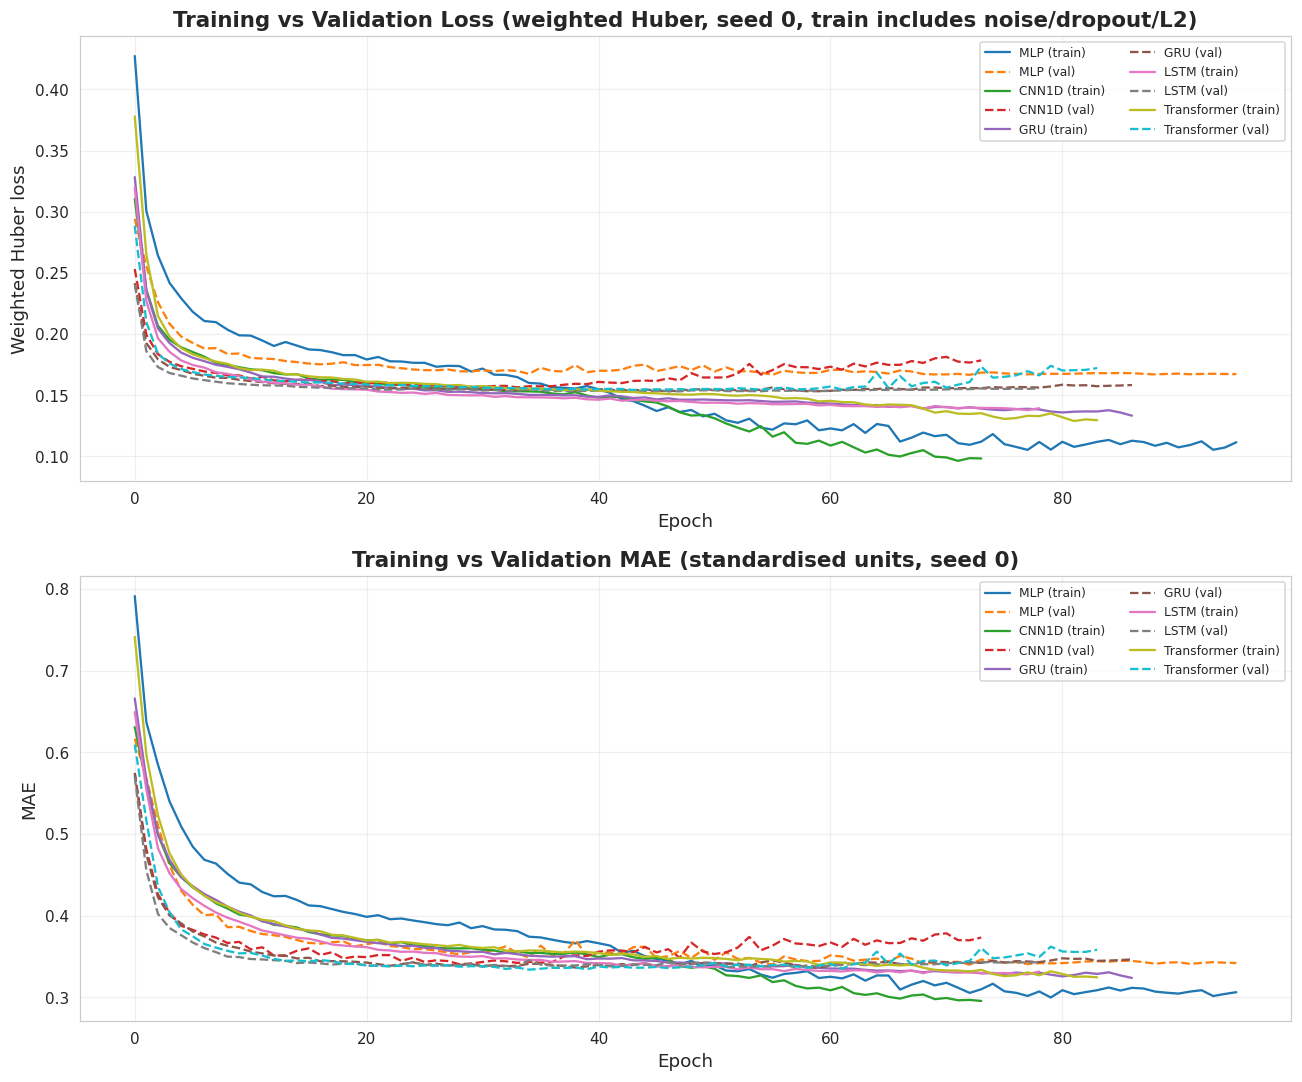

In [24]:
# 12.1 Training / validation loss curves for all models
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=False)
for name, hist in histories.items():
    axes[0].plot(hist["loss"], label=f"{name} (train)")
    axes[0].plot(hist["val_loss"], linestyle="--", label=f"{name} (val)")
    axes[1].plot(hist["mae"], label=f"{name} (train)")
    axes[1].plot(hist["val_mae"], linestyle="--", label=f"{name} (val)")
axes[0].set_title("Training vs Validation Loss (weighted Huber, seed 0, train includes noise/dropout/L2)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Weighted Huber loss"); axes[0].legend(fontsize=8, ncol=2)
axes[1].set_title("Training vs Validation MAE (standardised units, seed 0)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MAE"); axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
savefig("training_curves_all_models.png")
plt.show()


Plotting best model (selected by validation MPJPE): Transformer
Saved figure -> figures/pred_vs_true_Transformer_cv0x.png


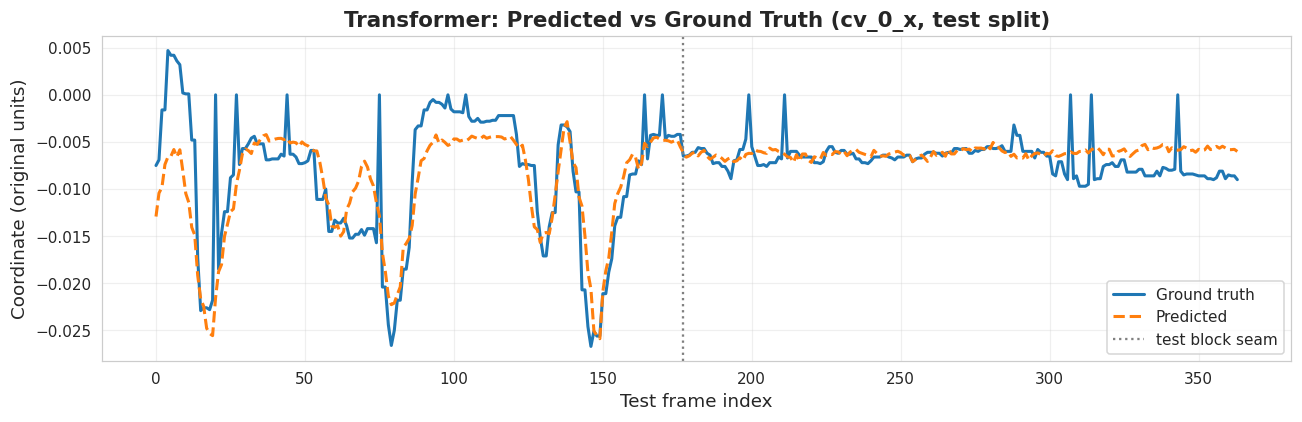

In [25]:
# 12.2 Predicted vs ground truth over time, for one representative coordinate (best model)
print(f"Plotting best model (selected by validation MPJPE): {best_name}")

y_true = results[best_name]["test"]["y_true"]
y_pred = results[best_name]["test"]["y_pred"]
joint_idx = pose_cols.index("cv_0_x")  # head x-coordinate, as an example trace

plt.figure(figsize=(12, 4))
plt.plot(y_true[:, joint_idx], label="Ground truth", linewidth=2)
plt.plot(y_pred[:, joint_idx], label="Predicted", linewidth=2, linestyle="--")
for k, sm in enumerate(TEST_SEAMS):
    plt.axvline(sm, color="gray", linestyle=":", label="test block seam" if k == 0 else None)
plt.title(f"{best_name}: Predicted vs Ground Truth (cv_0_x, test split)")
plt.xlabel("Test frame index"); plt.ylabel("Coordinate (original units)")
plt.legend()
plt.tight_layout()
savefig(f"pred_vs_true_{best_name}_cv0x.png")
plt.show()


Saved figure -> figures/parity_plot_Transformer.png


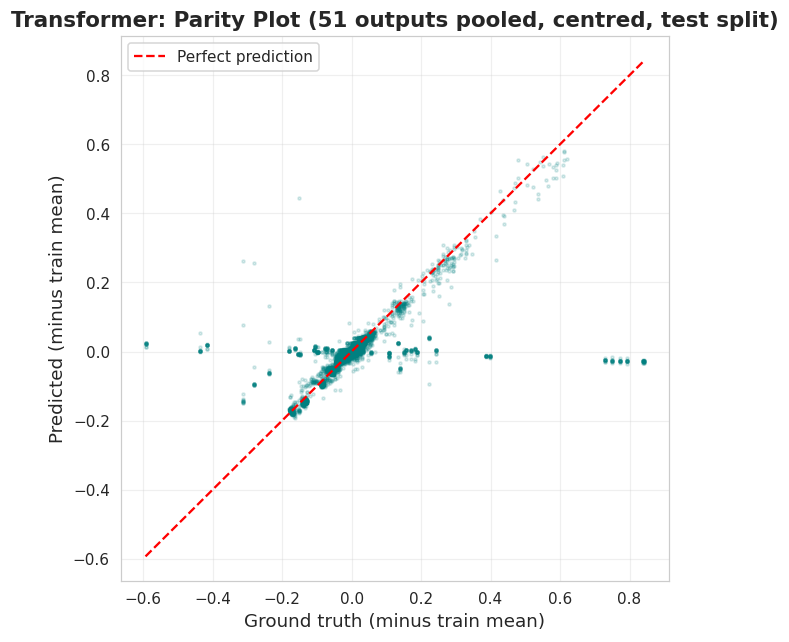

In [26]:
# 12.3 Parity plot, best model. Each column is centred on its train mean first; otherwise the
# large between-joint offsets (head y vs ankle y) make any model look perfect.
tr_mean = pose_scaler.mean_
yt_c = (y_true - tr_mean).flatten()
yp_c = (y_pred - tr_mean).flatten()
plt.figure(figsize=(6, 6))
plt.scatter(yt_c, yp_c, s=4, alpha=0.15, color="teal")
lims = [min(yt_c.min(), yp_c.min()), max(yt_c.max(), yp_c.max())]
plt.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Ground truth (minus train mean)"); plt.ylabel("Predicted (minus train mean)")
plt.title(f"{best_name}: Parity Plot (51 outputs pooled, centred, test split)")
plt.legend()
plt.tight_layout()
savefig(f"parity_plot_{best_name}.png")
plt.show()


Saved figure -> figures/residuals_Transformer.png


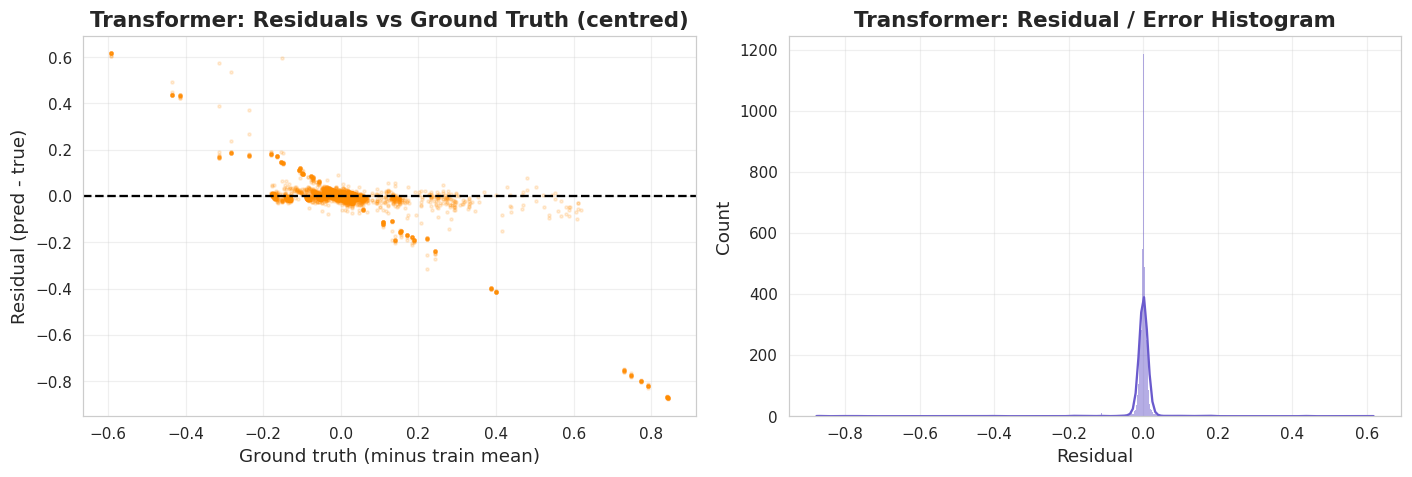

In [27]:
# 12.4 Residual plot & error histogram, best model
residuals = (y_pred - y_true).flatten()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(yt_c, residuals, s=4, alpha=0.15, color="darkorange")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title(f"{best_name}: Residuals vs Ground Truth (centred)")
axes[0].set_xlabel("Ground truth (minus train mean)"); axes[0].set_ylabel("Residual (pred - true)")

sns.histplot(residuals, kde=True, ax=axes[1], color="slateblue")
axes[1].set_title(f"{best_name}: Residual / Error Histogram")
axes[1].set_xlabel("Residual")
plt.tight_layout()
savefig(f"residuals_{best_name}.png")
plt.show()


Saved figure -> figures/joint_wise_mpjpe_Transformer.png


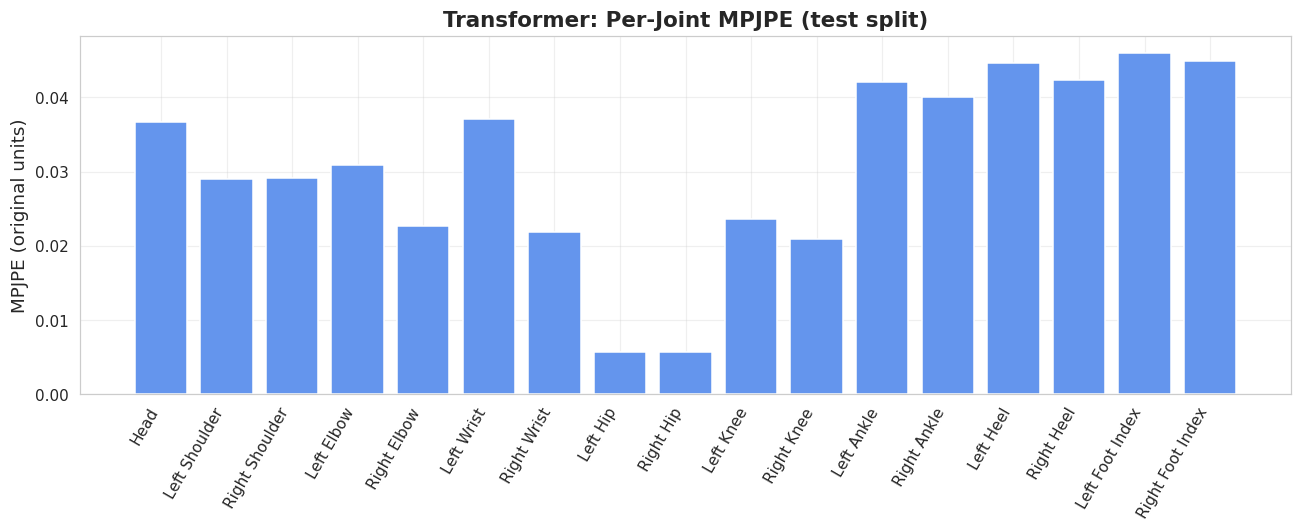

In [28]:
# 12.5 Joint-wise MPJPE bar chart, best model
per_joint = results[best_name]["test"]["per_joint_mpjpe"]
plt.figure(figsize=(12, 5))
plt.bar(KEYPOINT_NAMES, per_joint, color="cornflowerblue")
plt.xticks(rotation=60, ha="right")
plt.ylabel("MPJPE (original units)")
plt.title(f"{best_name}: Per-Joint MPJPE (test split)")
plt.tight_layout()
savefig(f"joint_wise_mpjpe_{best_name}.png")
plt.show()


### 12.6 Skeleton Visualization

Saved figure -> figures/Transformer_3x3_pose_projection_rearranged.png


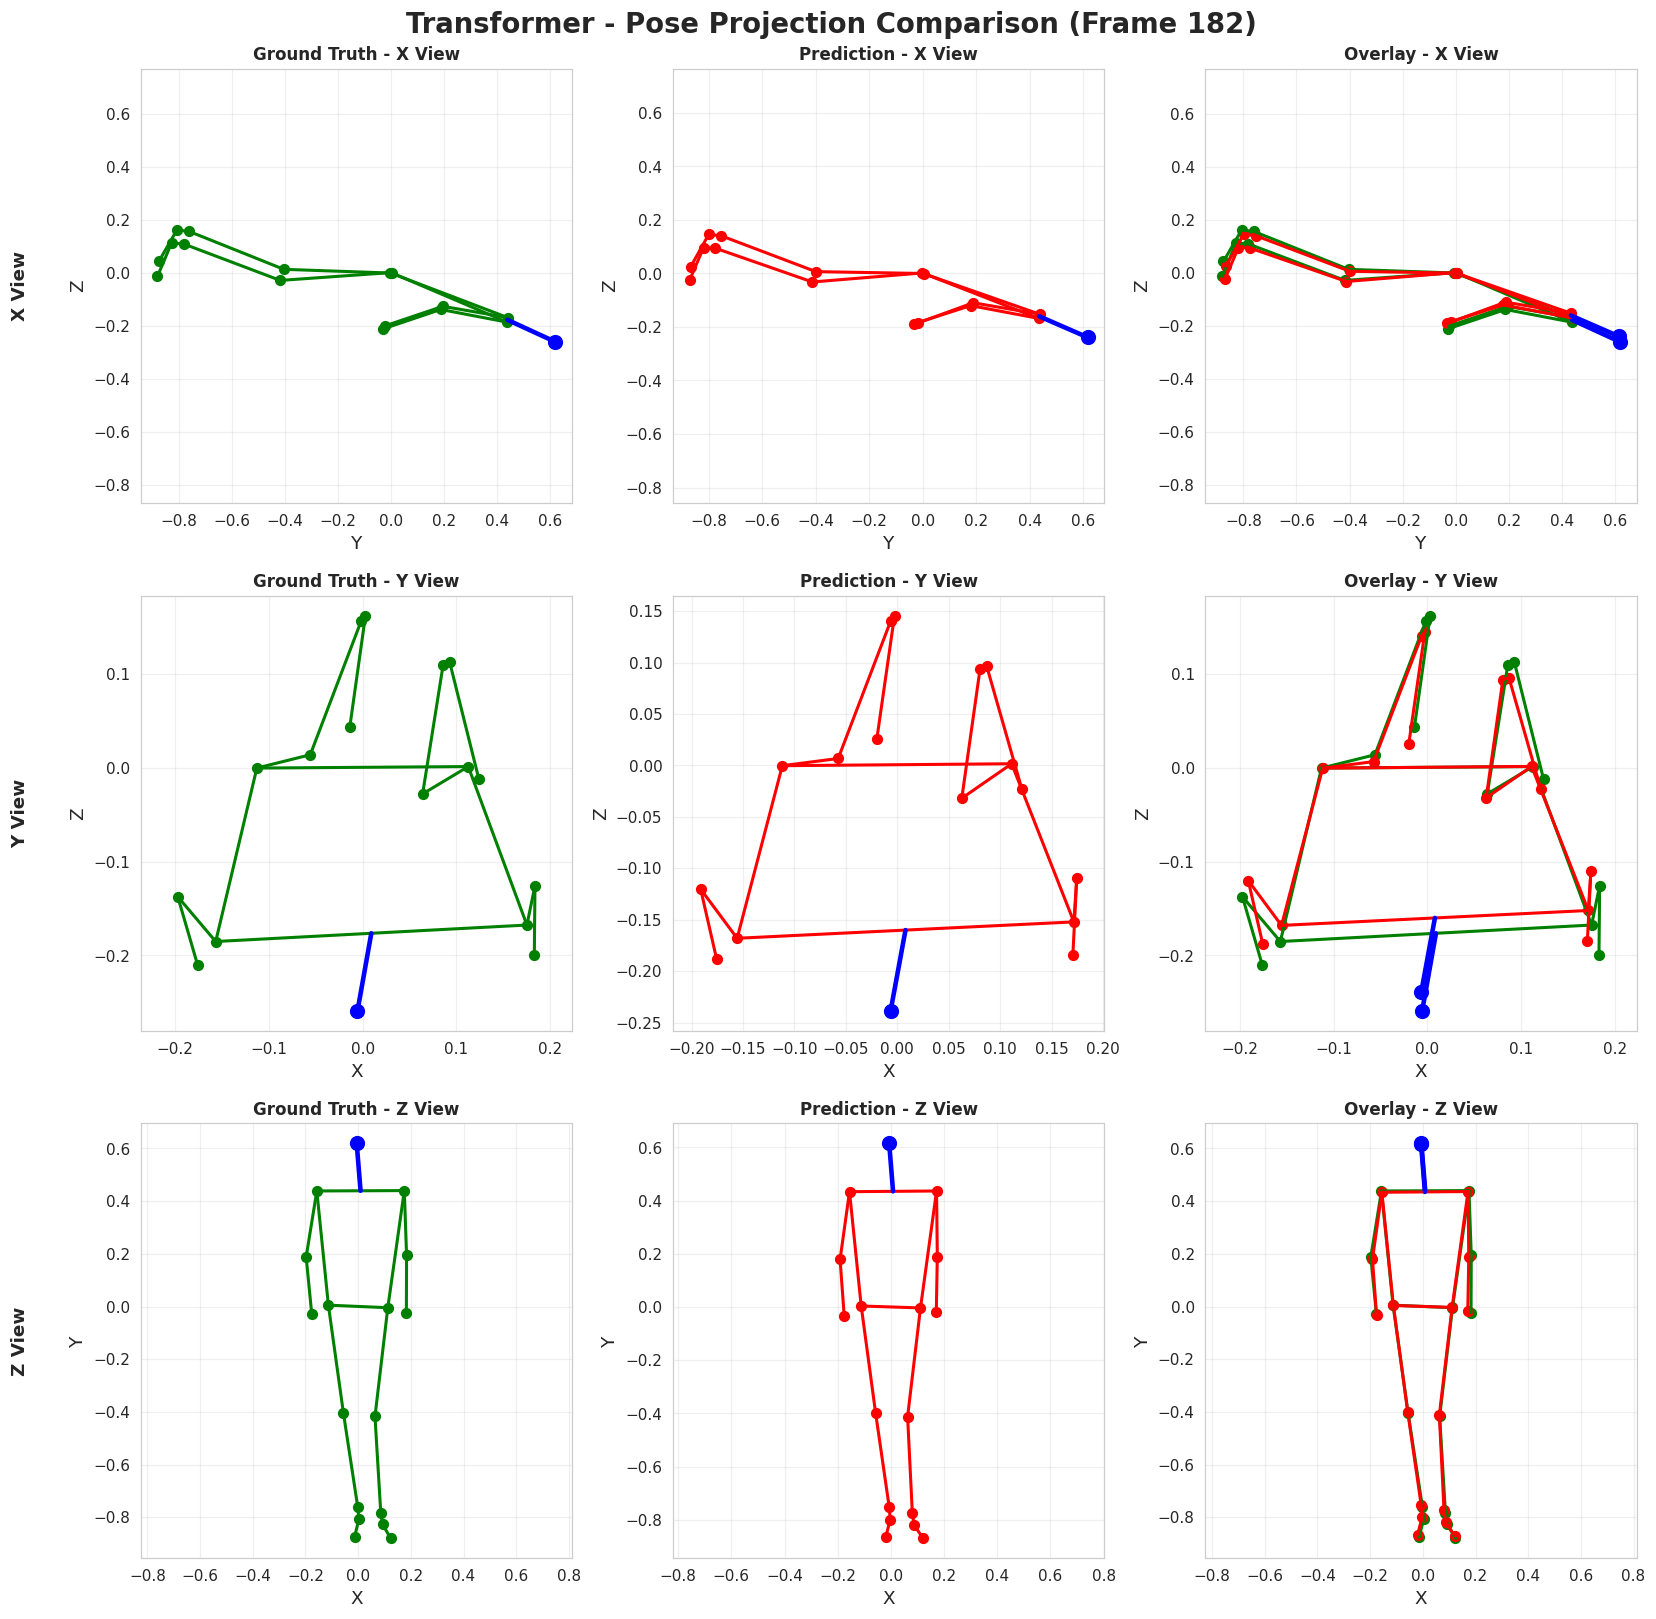

In [29]:
# ==========================================================
# 3x3 Skeleton Projection Visualization
# Rows:    X view, Y view, Z view
# Columns: Ground Truth, Prediction, Overlay
#
# Head = BLUE
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
# ----------------------------------------------------------
# Skeleton connections
# ----------------------------------------------------------
SKELETON_CONNECTIONS = [
    # Shoulder line
    (1, 2),
    # Left arm
    (1, 3),
    (3, 5),
    # Right arm
    (2, 4),
    (4, 6),
    # Torso
    (1, 7),
    (2, 8),
    (7, 8),
    # Left leg
    (7, 9),
    (9, 11),
    (11, 13),
    (13, 15),
    # Right leg
    (8, 10),
    (10, 12),
    (12, 14),
    (14, 16),
]
# ----------------------------------------------------------
# Draw 2D projection
# ----------------------------------------------------------
def plot_projection(ax, coords, body_color, view, title=""):
    # -----------------------------------
    # Select projection axis
    # -----------------------------------
    if view == "X":
        # Looking along X axis
        x = coords[:, 1]
        y = coords[:, 2]
        xlabel = "Y"
        ylabel = "Z"
    elif view == "Y":
        # Looking along Y axis
        x = coords[:, 0]
        y = coords[:, 2]
        xlabel = "X"
        ylabel = "Z"
    elif view == "Z":
        # Looking along Z axis
        x = coords[:, 0]
        y = coords[:, 1]
        xlabel = "X"
        ylabel = "Y"
    # -----------------------------------
    # Draw body joints except head
    # -----------------------------------
    ax.scatter(
        x[1:],
        y[1:],
        color=body_color,
        s=40
    )
    # -----------------------------------
    # Draw head in BLUE
    # -----------------------------------
    ax.scatter(
        x[0],
        y[0],
        color="blue",
        s=80
    )
    # -----------------------------------
    # Draw bones
    # -----------------------------------
    for a, b in SKELETON_CONNECTIONS:
        ax.plot(
            [x[a], x[b]],
            [y[a], y[b]],
            color=body_color,
            linewidth=2
        )
    # -----------------------------------
    # Head -> shoulder midpoint
    # -----------------------------------
    shoulder_mid = (coords[1] + coords[2]) / 2
    if view == "X":
        hx = coords[0,1]
        hy = coords[0,2]
        sx = shoulder_mid[1]
        sy = shoulder_mid[2]
    elif view == "Y":
        hx = coords[0,0]
        hy = coords[0,2]
        sx = shoulder_mid[0]
        sy = shoulder_mid[2]
    elif view == "Z":
        hx = coords[0,0]
        hy = coords[0,1]
        sx = shoulder_mid[0]
        sy = shoulder_mid[1]
    ax.plot(
        [hx, sx],
        [hy, sy],
        color="blue",
        linewidth=3
    )
    ax.set_title(title, fontsize=11, weight="bold")

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    ax.axis("equal")
    ax.grid(True)
# ==========================================================
# Select frame
# ==========================================================
frame_idx = len(y_true)//2

true_coords = y_true[frame_idx].reshape(N_JOINTS,3)

pred_coords = y_pred[frame_idx].reshape(N_JOINTS,3)

# ==========================================================
# Create 3x3 figure
# Rows  : X, Y, Z views
# Columns : Ground Truth, Prediction, Overlay
# ==========================================================
fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 15)
)
views = ["X", "Y", "Z"]
# ==========================================================
# Column 1: Ground Truth
# ==========================================================
for row, view in enumerate(views):
    plot_projection(
        axes[row, 0],
        true_coords,
        "green",
        view,
        f"Ground Truth - {view} View"
    )
# ==========================================================
# Column 2: Prediction
# ==========================================================
for row, view in enumerate(views):
    plot_projection(
        axes[row, 1],
        pred_coords,
        "red",
        view,
        f"Prediction - {view} View"
    )
# ==========================================================
# Column 3: Overlay
# ==========================================================
for row, view in enumerate(views):
    plot_projection(
        axes[row, 2],
        true_coords,
        "green",
        view
        
    )
    plot_projection(
        axes[row, 2],
        pred_coords,
        "red",
        view,
        f"Overlay - {view} View"
    )

# ==========================================================
# Row labels
# ==========================================================
for r, v in enumerate(views):          # row labels without overwriting each axis' own y-label
    axes[r, 0].annotate(f"{v} View", xy=(-0.28, 0.5), xycoords="axes fraction",
                        rotation=90, va="center", ha="center", fontsize=12, weight="bold")
plt.suptitle(
    f"{best_name} - Pose Projection Comparison (Frame {frame_idx})",
    fontsize=18,
    weight="bold"
)
plt.tight_layout()
savefig(
    f"{best_name}_3x3_pose_projection_rearranged.png"
)
plt.show()

### 12.7 Animated Skeleton Visualization

Saved animation -> figures/skeleton_animation_Z_view_Transformer.gif


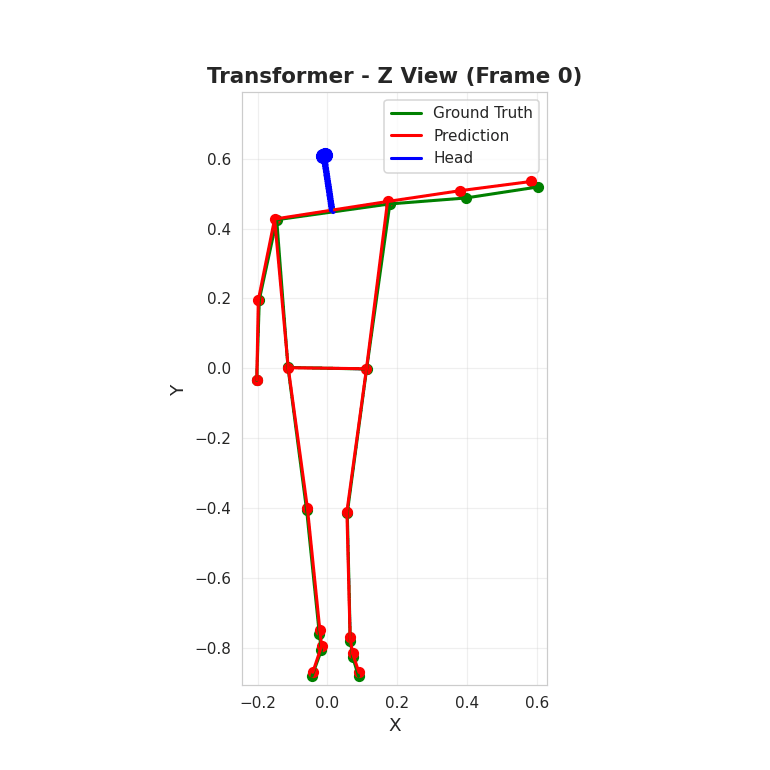

In [30]:
from IPython.display import Image, display
# ==========================================================
# Skeleton Animation (Z View / XY Projection)
# ==========================================================
N_ANIM_FRAMES = min(200, len(y_true))
fig, ax = plt.subplots(figsize=(7, 7))
# ----------------------------------------------------------
# Draw one projected skeleton
# ----------------------------------------------------------
def draw_skeleton_xy(ax, coords, body_color):
    x = coords[:, 0]   # X
    y = coords[:, 1]   # Y
    # Body joints
    ax.scatter(x[1:], y[1:], color=body_color, s=40)
    # Head
    ax.scatter(x[0], y[0], color="blue", s=80)
    # Body bones
    for a, b in SKELETON_CONNECTIONS:
        ax.plot(
            [x[a], x[b]],
            [y[a], y[b]],
            color=body_color,
            linewidth=2
        )
    # Head -> shoulder midpoint
    shoulder_mid = (coords[1] + coords[2]) / 2
    ax.plot(
        [coords[0,0], shoulder_mid[0]],
        [coords[0,1], shoulder_mid[1]],
        color="blue",
        linewidth=3
    )
# ----------------------------------------------------------
# Fixed axis limits
# ----------------------------------------------------------
all_points = np.vstack([y_true.reshape(-1,3), y_pred.reshape(-1,3)])
xmin, ymin = all_points[:, :2].min(axis=0)
xmax, ymax = all_points[:, :2].max(axis=0)
margin = 0.02
xmin -= margin
ymin -= margin
xmax += margin
ymax += margin
# ----------------------------------------------------------
# Animation update
# ----------------------------------------------------------
def update(frame):
    ax.clear()
    true_coords = y_true[frame].reshape(N_JOINTS, 3)
    pred_coords = y_pred[frame].reshape(N_JOINTS, 3)
    draw_skeleton_xy(ax, true_coords, "green")
    draw_skeleton_xy(ax, pred_coords, "red")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"{best_name} - Z View (Frame {frame})")
    ax.grid(True)
    ax.plot([], [], color="green", lw=2, label="Ground Truth")
    ax.plot([], [], color="red", lw=2, label="Prediction")
    ax.plot([], [], color="blue", lw=2, label="Head")
    ax.legend(loc="upper right")
    return ax,

# ----------------------------------------------------------
# Create animation
# ----------------------------------------------------------
anim = animation.FuncAnimation(
    fig,
    update,
    frames=N_ANIM_FRAMES,
    interval=50,      # 20 Hz = real time
    blit=False
)

# ----------------------------------------------------------
# Save animation
# ----------------------------------------------------------
anim_path = os.path.join(
    DIR_FIGURES,
    f"skeleton_animation_Z_view_{best_name}.gif"
)

anim.save(
    anim_path,
    writer=animation.PillowWriter(fps=20)
)

plt.close(fig)
print(f"Saved animation -> {anim_path}")
# ----------------------------------------------------------
# Display GIF in notebook
# ----------------------------------------------------------
display(Image(filename=anim_path))


## 13. Model Comparison & Ranking

In [31]:
comparison_rows = []
for name, r in results.items():
    comparison_rows.append({
        "Model": name,
        "Parameters": r["n_params"],
        "Training Time (s)": round(r["training_time"], 2),
        "Inference Time (s, test set)": round(r["inference_time"], 4),
        "Inference FPS": round(r["fps"], 1),
        "Val MPJPE": round(r["val"]["mpjpe"], 5),
        "Test MAE": round(r["test"]["mae"], 5),
        "Test RMSE": round(r["test"]["rmse"], 5),
        "Test MPJPE": round(r["test"]["mpjpe"], 5),
        "Test R2": round(r["test"]["r2"], 5),
        "Test R2 OOS": round(r["test"]["r2_oos"], 5),
        "Test R2 active": round(r["test"]["r2_active"], 5),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("Val MPJPE").reset_index(drop=True)
comparison_df.to_csv(os.path.join(DIR_RESULTS, "model_comparison.csv"), index=False)

assert comparison_df.iloc[0]["Model"] == best_model_name
print(f"Best model (lowest validation MPJPE): {best_model_name}")
print("Parameters are per ensemble member. FPS is for the full ensemble, batch prediction.")
display(comparison_df.style.highlight_min(subset=["Test MAE", "Test RMSE", "Test MPJPE"],
                                           color="lightgreen")
                             .highlight_max(subset=["Test R2", "Test R2 OOS", "Test R2 active"], color="lightgreen"))


Best model (lowest validation MPJPE): Transformer
Parameters are per ensemble member. FPS is for the full ensemble, batch prediction.


,Model,Parameters,Training Time (s),"Inference Time (s, test set)",Inference FPS,Val MPJPE,Test MAE,Test RMSE,Test MPJPE,Test R2,Test R2 OOS,Test R2 active
0,Transformer,17011,116.660000,0.307600,1183.200000,0.035100,0.013760,0.064260,0.030800,0.316370,0.342360,0.218440
1,CNN1D,20691,75.480000,0.307900,1182.300000,0.035500,0.013990,0.064190,0.031260,0.317920,0.343850,0.219970
2,MLP,50099,76.590000,0.305500,1191.500000,0.035510,0.013650,0.064280,0.030670,0.316000,0.342000,0.219290
3,LSTM,34835,82.970000,0.324600,1121.200000,0.035750,0.013820,0.064210,0.030930,0.317480,0.343430,0.219760
4,GRU,28947,93.010000,0.318600,1142.400000,0.035860,0.013840,0.064290,0.030940,0.315790,0.341800,0.218560


### 13.1 R2 diagnostics per joint (best model)

Shows which joints pull R² down, and whether they move at all in the test slice.
A joint with `Test / Train` below 0.25 is essentially static in this split, so its R² is not meaningful.


In [32]:
yt = results[best_model_name]["test"]["y_true"]
yp = results[best_model_name]["test"]["y_pred"]
tr_mean, tr_std = pose_scaler.mean_, pose_scaler.scale_

rows = []
for j, jn in enumerate(KEYPOINT_NAMES):
    sl = slice(3 * j, 3 * j + 3)
    sse   = ((yt[:, sl] - yp[:, sl]) ** 2).sum()
    sst   = ((yt[:, sl] - yt[:, sl].mean(axis=0)) ** 2).sum()
    sse_b = ((yt[:, sl] - tr_mean[sl]) ** 2).sum()
    test_std  = np.sqrt(yt[:, sl].var(axis=0).sum())
    train_std = np.sqrt((tr_std[sl] ** 2).sum())
    rows.append({
        "Joint": jn,
        "Test motion (std)": round(test_std, 4),
        "Train motion (std)": round(train_std, 4),
        "Test / Train": round(test_std / train_std, 2),
        "R2 (var-weighted)": round(1 - sse / sst, 3) if sst > 0 else float("nan"),
        "R2 OOS": round(1 - sse / sse_b, 3),
    })

r2_diag_df = pd.DataFrame(rows)
r2_diag_df.to_csv(os.path.join(DIR_RESULTS, "r2_per_joint_diagnostics.csv"), index=False)
display(r2_diag_df)


,Joint,Test motion (std),Train motion (std),Test / Train,R2 (var-weighted),R2 OOS
0,Head,0.1249,0.1339,0.93,-0.016,-0.013
1,Left Shoulder,0.0966,0.1047,0.92,0.026,0.029
2,Right Shoulder,0.0931,0.0999,0.93,-0.011,-0.003
3,Left Elbow,0.1594,0.1884,0.85,0.819,0.832
4,Right Elbow,0.0609,0.0671,0.91,0.133,0.138
5,Left Wrist,0.2815,0.3314,0.85,0.925,0.933
6,Right Wrist,0.0832,0.0947,0.88,0.616,0.633
7,Left Hip,0.0211,0.0225,0.94,-0.002,0.006
8,Right Hip,0.0212,0.0226,0.94,-0.005,0.003
9,Left Knee,0.0789,0.0841,0.94,-0.022,-0.020


Saved figure -> figures/model_comparison_bars.png


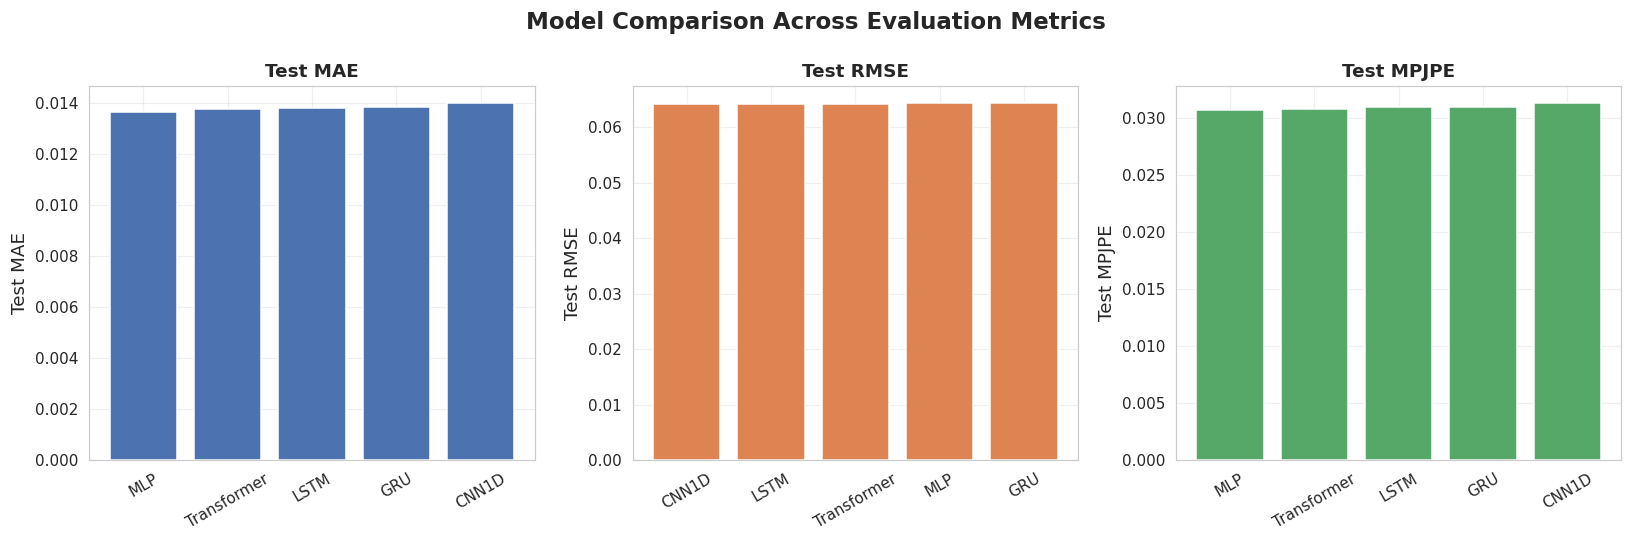

In [33]:
# Comparison bar charts (MAE, RMSE, MPJPE)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics_to_plot = ["Test MAE", "Test RMSE", "Test MPJPE"]
colors = ["#4C72B0", "#DD8452", "#55A868"]

for ax, metric, color in zip(axes, metrics_to_plot, colors):

    ordered = comparison_df.sort_values(metric, ascending=True)

    ax.bar(
        ordered["Model"],
        ordered[metric],
        color=color
    )

    ax.set_title(metric, fontsize=12, fontweight="bold")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)

plt.suptitle(
    "Model Comparison Across Evaluation Metrics",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

savefig("model_comparison_bars.png")

plt.show()

## 14. Explainability - Permutation Importance

For each of the 30 IMU input channels we shuffle that channel's values across the test windows (independently of all other channels, `N_REPEATS` times) and measure how much the test MPJPE degrades. A larger degradation means the model relies more on that channel. Correlated channels share importance, so read the ranking as indicative, not exact. A SHAP-style analysis would be a natural extension.


Saved figure -> figures/permutation_importance.png


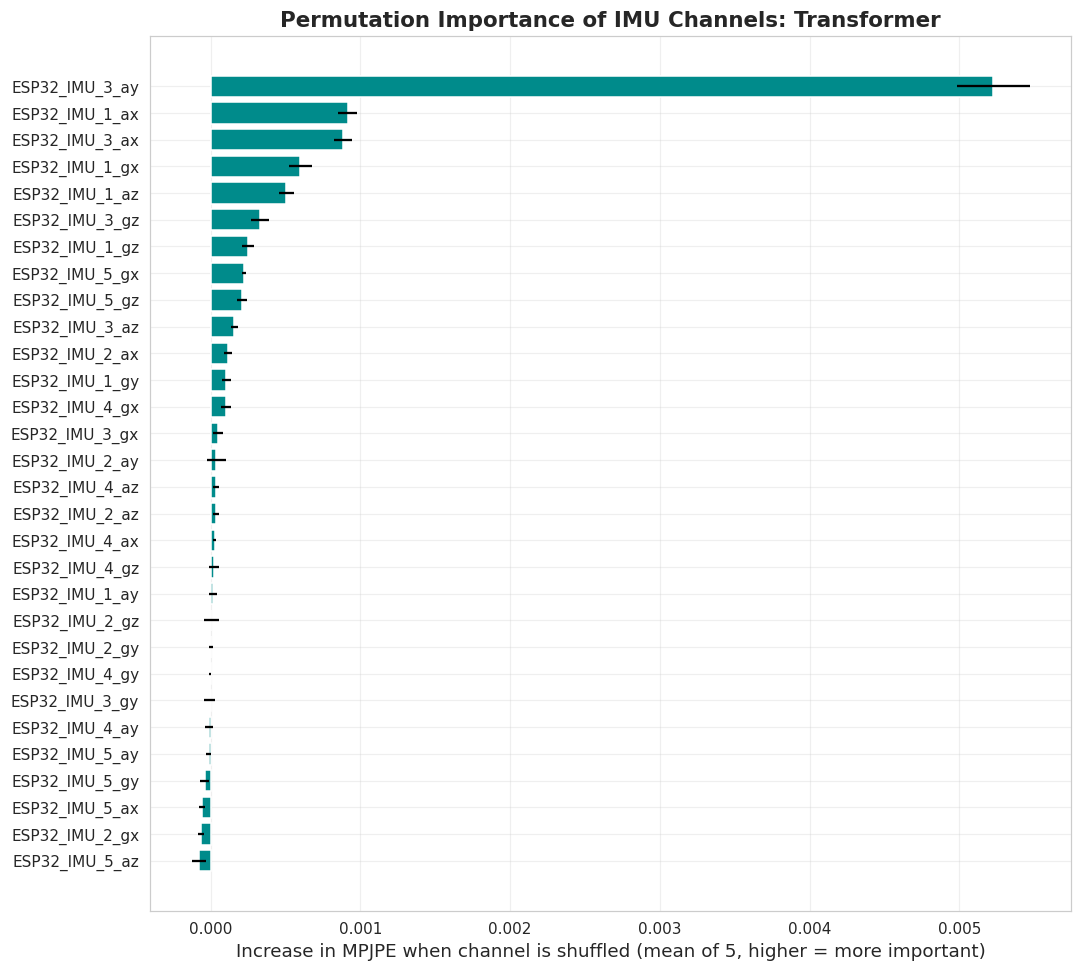

Top 5 most important IMU channels:


,IMU Channel,MPJPE Increase,Std
0,ESP32_IMU_3_ay,0.005228,0.000241
1,ESP32_IMU_1_ax,0.000915,0.000063
2,ESP32_IMU_3_ax,0.000882,0.000059
3,ESP32_IMU_1_gx,0.000598,0.000076
4,ESP32_IMU_1_az,0.000507,0.000049


In [34]:
best_model = trained_models[best_model_name]
baseline_mpjpe = results[best_model_name]["test"]["mpjpe"]
y_true_best = results[best_model_name]["test"]["y_true"]

N_REPEATS = 5
importance, importance_std = [], []
rng = np.random.default_rng(SEED)
for feat_idx, feat_name in enumerate(imu_cols):
    deltas = []
    for _ in range(N_REPEATS):
        X_shuf = X_test.copy()
        perm = rng.permutation(len(X_shuf))
        X_shuf[:, :, feat_idx] = X_test[perm, :, feat_idx]      # shuffle across samples, keep temporal shape
        y_shuf = pose_scaler.inverse_transform(np.asarray(best_model.predict(X_shuf, verbose=0), dtype="float64"))
        deltas.append(mpjpe(y_true_best, y_shuf)[0] - baseline_mpjpe)
    importance.append(np.mean(deltas)); importance_std.append(np.std(deltas))

importance_df = pd.DataFrame({"IMU Channel": imu_cols, "MPJPE Increase": importance, "Std": importance_std})
importance_df = importance_df.sort_values("MPJPE Increase", ascending=False).reset_index(drop=True)
importance_df.to_csv(os.path.join(DIR_RESULTS, "permutation_importance.csv"), index=False)

plt.figure(figsize=(10, 9))
plt.barh(importance_df["IMU Channel"], importance_df["MPJPE Increase"], xerr=importance_df["Std"], color="darkcyan")
plt.gca().invert_yaxis()
plt.xlabel(f"Increase in MPJPE when channel is shuffled (mean of {N_REPEATS}, higher = more important)")
plt.title(f"Permutation Importance of IMU Channels: {best_model_name}")
plt.tight_layout()
savefig("permutation_importance.png")
plt.show()

print("Top 5 most important IMU channels:")
display(importance_df.head())


## 15. Save All Artifacts

In [35]:
# Best model: EnsembleModel.save writes <stem>_member{i}.keras (one file per seed)
best_model.save(os.path.join(DIR_MODELS, "best_model_overall.keras"))

# Everything inference needs besides the weights and scalers
with open(os.path.join(DIR_RESULTS, "inference_config.json"), "w") as f:
    json.dump(dict(best_model=best_model_name, window_size=WINDOW_SIZE, n_members=len(best_model.members),
                   split_mode=SPLIT_MODE, imu_cols=imu_cols, pose_cols=pose_cols), f, indent=2)

# Scalers were already saved in Section 7 (imu_scaler.joblib, pose_scaler.joblib)

# Predictions for every model on the test split
for name, r in results.items():
    np.save(os.path.join(DIR_RESULTS, f"y_pred_test_{name}.npy"), r["test"]["y_pred"])
np.save(os.path.join(DIR_RESULTS, "y_true_test.npy"), results[best_model_name]["test"]["y_true"])

# Metrics already saved as model_comparison.csv (Section 13) and training_history.json (Section 10)

print("Saved:")
print(f"  - Best model (ensemble) -> {DIR_MODELS}/best_model_overall_member*.keras")
print(f"  - Per-seed checkpoints  -> {DIR_MODELS}/<Model>_seed<k>_best.keras")
print(f"  - Inference config      -> {DIR_RESULTS}/inference_config.json")
print(f"  - Scalers               -> {DIR_SCALERS}/imu_scaler.joblib, pose_scaler.joblib")
print(f"  - Training history      -> {DIR_RESULTS}/training_history.json (seed 0)")
print(f"  - Comparison table      -> {DIR_RESULTS}/model_comparison.csv")
print(f"  - Permutation import.   -> {DIR_RESULTS}/permutation_importance.csv")
print(f"  - Predictions           -> {DIR_RESULTS}/y_pred_test_<Model>.npy, y_true_test.npy")
print(f"  - Figures               -> {DIR_FIGURES}/*.png, *.gif")


Saved:
  - Best model (ensemble) -> saved_models/best_model_overall_member*.keras
  - Per-seed checkpoints  -> saved_models/<Model>_seed<k>_best.keras
  - Inference config      -> results/inference_config.json
  - Scalers               -> saved_scalers/imu_scaler.joblib, pose_scaler.joblib
  - Training history      -> results/training_history.json (seed 0)
  - Comparison table      -> results/model_comparison.csv
  - Permutation import.   -> results/permutation_importance.csv
  - Predictions           -> results/y_pred_test_<Model>.npy, y_true_test.npy
  - Figures               -> figures/*.png, *.gif


## 16. Inference on New IMU Data

The function below loads the saved best model and scalers, accepts a **new** raw IMU
window (a DataFrame with the same 30 IMU columns, `WINDOW_SIZE` rows, most recent frame last),
and returns predicted pose landmarks in original units. We demonstrate it on a slice of the
held-out test data standing in for "new" incoming IMU data, and export the result to CSV.


In [36]:
def predict_pose_from_imu(imu_window_df, model=None, imu_scaler=imu_scaler,
                           pose_scaler=pose_scaler, imu_columns=imu_cols,
                           pose_columns=pose_cols, model_path=None):
    """
    Run inference for a single window of raw IMU data.

    imu_window_df : pandas.DataFrame with columns == imu_columns and WINDOW_SIZE rows,
                     ordered oldest -> newest.
    model         : an already-loaded EnsembleModel / keras.Model (optional)
    model_path    : e.g. "saved_models/best_model_overall.keras"; loaded as an ensemble
                     (<stem>_member*.keras) when `model` is None.

    Returns
    -------
    pandas.Series indexed by pose_columns, with the predicted pose landmark values
    in original (unscaled) units.
    """
    if model is None:
        model = EnsembleModel.load(model_path)

    X_new = imu_window_df[imu_columns].values.astype("float32")
    assert X_new.shape[0] == WINDOW_SIZE, f"Expected {WINDOW_SIZE} rows, got {X_new.shape[0]}"

    X_new_scaled = imu_scaler.transform(X_new)[None, ...]     # -> (1, WINDOW_SIZE, n_features)
    y_pred_scaled = model.predict(X_new_scaled, verbose=0)
    y_pred = pose_scaler.inverse_transform(y_pred_scaled)[0]
    return pd.Series(y_pred, index=pose_columns)


# --- Demonstration on a held-out slice of the test split (stands in for "new" IMU data) ---
demo_start = next(st for nm, st, en in segments if nm == "test")   # first held-out test segment
demo_end   = demo_start + WINDOW_SIZE
demo_raw_df = df[imu_cols].iloc[demo_start:demo_end].reset_index(drop=True)
predicted_pose = predict_pose_from_imu(demo_raw_df, model=best_model)

print("Predicted pose landmarks for the demo window:")
display(predicted_pose.to_frame("predicted_value").T)

# sanity check against the ground truth at the window's last frame (the frame the model predicts)
true_pose = df[pose_cols].iloc[demo_end - 1].values
demo_mpjpe = np.linalg.norm((predicted_pose.values - true_pose).reshape(-1, 3), axis=1).mean()
print(f"Demo MPJPE vs ground truth at the last frame: {demo_mpjpe:.5f}")

predicted_pose.to_frame("predicted_value").T.to_csv(
    os.path.join(DIR_RESULTS, "inference_demo_prediction.csv"), index=False)
print(f"\nExported -> {DIR_RESULTS}/inference_demo_prediction.csv")


Predicted pose landmarks for the demo window:


,cv_0_x,cv_0_y,cv_0_z,cv_1_x,cv_1_y,cv_1_z,cv_2_x,cv_2_y,cv_2_z,cv_3_x,...,cv_13_z,cv_14_x,cv_14_y,cv_14_z,cv_15_x,cv_15_y,cv_15_z,cv_16_x,cv_16_y,cv_16_z
predicted_value,-0.012917,0.608957,-0.255941,0.172275,0.477783,-0.170077,-0.151134,0.427438,-0.180699,0.37903,...,0.123562,-0.016457,-0.794823,0.19616,0.090478,-0.87064,-0.004742,-0.04186,-0.870325,0.072613


Demo MPJPE vs ground truth at the last frame: 0.01424

Exported -> results/inference_demo_prediction.csv


## 17. To run inference on a genuinely new recording

In [37]:
#new_df = pd.read_csv("new_imu_recording.csv")                      # same IMU column names, sorted by time
#cfg = json.load(open("results/inference_config.json"))
#loaded_model       = EnsembleModel.load("saved_models/best_model_overall.keras")   # loads every *_member*.keras
#loaded_imu_scaler  = joblib.load("saved_scalers/imu_scaler.joblib")
#loaded_pose_scaler = joblib.load("saved_scalers/pose_scaler.joblib")
#window = new_df.iloc[-cfg["window_size"]:]                         # most recent window_size frames
#pose = predict_pose_from_imu(window, model=loaded_model, imu_scaler=loaded_imu_scaler, pose_scaler=loaded_pose_scaler)


## 18. Final Discussion

In [38]:
from IPython.display import display
print("\n" + "=" * 50)
print("             MODEL COMPARISON SUMMARY")
print("=" * 50)
# ============================================================
# TABLE 1: PERFORMANCE METRICS
# ============================================================
table1_df = comparison_df[
    ["Model", "Test MAE", "Test RMSE", "Test MPJPE", "Test R2"]
].copy()

table1_df.columns = [
    "Model", "MAE", "RMSE", "MPJPE", "R²"
]
# Format numeric values
table1_display = table1_df.copy()

for col in ["MAE", "RMSE", "MPJPE", "R²"]:
    table1_display[col] = table1_display[col].map(lambda x: f"{x:.5f}")

print("\nTABLE 1: TEST PERFORMANCE")
display(table1_display)

# ============================================================
# TABLE 2: GENERALIZATION & EFFICIENCY
# ============================================================

table2_df = comparison_df[
    ["Model", "Test R2 OOS", "Test R2 active",
     "Inference FPS", "Parameters"]
].copy()

table2_df.columns = [
    "Model", "R² OOS", "R² Active", "FPS", "Parameters"
]

# Format numeric values
table2_display = table2_df.copy()

table2_display["R² OOS"] = table2_display["R² OOS"].map(
    lambda x: f"{x:.5f}"
)

table2_display["R² Active"] = table2_display["R² Active"].map(
    lambda x: f"{x:.5f}"
)

table2_display["FPS"] = table2_display["FPS"].map(
    lambda x: f"{x:.2f}"
)

table2_display["Parameters"] = table2_display["Parameters"].map(
    lambda x: f"{x:,}"
)

print("\nTABLE 2: GENERALIZATION & COMPUTATIONAL PERFORMANCE")
display(table2_display)
# ============================================================
# BEST MODEL SUMMARY
# ============================================================
best_row = comparison_df[
    comparison_df["Model"] == best_model_name
].iloc[0]

print("\n" + "=" * 50)
print("                    BEST MODEL")
print("=" * 50)

best_summary = pd.DataFrame([
    ["Model", best_model_name],
    ["Test MAE", f"{best_row['Test MAE']:.5f}"],
    ["Test RMSE", f"{best_row['Test RMSE']:.5f}"],
    ["Test MPJPE", f"{best_row['Test MPJPE']:.5f}"],
    ["Test R² (Var-Weighted)", f"{best_row['Test R2']:.5f}"],
    ["Test R² OOS vs Train Mean", f"{best_row['Test R2 OOS']:.5f}"],
    ["Test R² Active Columns", f"{best_row['Test R2 active']:.5f}"],
    ["Inference Speed", f"{best_row['Inference FPS']:.2f} FPS"],
    ["Parameters", f"{best_row['Parameters']:,}"]
], columns=["Metric", "Result"])

display(best_summary)

print("=" * 50)


             MODEL COMPARISON SUMMARY

TABLE 1: TEST PERFORMANCE


,Model,MAE,RMSE,MPJPE,R²
0,Transformer,0.01376,0.06426,0.03080,0.31637
1,CNN1D,0.01399,0.06419,0.03126,0.31792
2,MLP,0.01365,0.06428,0.03067,0.31600
3,LSTM,0.01382,0.06421,0.03093,0.31748
4,GRU,0.01384,0.06429,0.03094,0.31579



TABLE 2: GENERALIZATION & COMPUTATIONAL PERFORMANCE


,Model,R² OOS,R² Active,FPS,Parameters
0,Transformer,0.34236,0.21844,1183.20,"17,011"
1,CNN1D,0.34385,0.21997,1182.30,"20,691"
2,MLP,0.34200,0.21929,1191.50,"50,099"
3,LSTM,0.34343,0.21976,1121.20,"34,835"
4,GRU,0.34180,0.21856,1142.40,"28,947"



                    BEST MODEL


,Metric,Result
0,Model,Transformer
1,Test MAE,0.01376
2,Test RMSE,0.06426
3,Test MPJPE,0.03080
4,Test R² (Var-Weighted),0.31637
5,Test R² OOS vs Train Mean,0.34236
6,Test R² Active Columns,0.21844
7,Inference Speed,1183.20 FPS
8,Parameters,"17,011"


### How to read these results

* **Selection vs reporting.** The best model is chosen on validation MPJPE. Test numbers are reported once and never used to choose.
* **Differences between models are small.** Check them against the seed-to-seed spread of the validation losses printed in Section 10 before claiming a winner. Without repeated runs or confidence intervals, treat close models as tied.
* **Compare with the references in Section 11.1.** If ExtraTrees on the last frame is close to the deep models, the temporal window adds little and the main signal is the current IMU posture.
* **Blocked split = interpolation.** Scores describe performance inside one recorded session. Re-run with `SPLIT_MODE = "chrono"` and report both.
* **Pseudo ground truth.** Targets are MediaPipe landmarks from one camera, not marker-based mocap. Model error is measured against labels with their own jitter and, if the Section 4 check shows repeated pose rows, a lower update rate than the IMUs.
* **One subject, one recording.** No claim about cross-subject or cross-session generalisation can be made from this data.
* **Units.** Parameter counts are per ensemble member. FPS is whole-ensemble batch prediction on this machine, not on-device latency.

**Limitations and future work:** leave-one-session-out and cross-subject evaluation, more recordings with varied motion, orientation fusion (for example Madgwick/Mahony) instead of raw accelerometer and gyroscope channels, bone-length constraints or temporal smoothing on the output, and latency measurement on the target hardware.


## 19. Export the Best Model to ONNX

The best model (chosen by validation MPJPE in Section 11) is an **ensemble of `N_SEEDS` Keras models**.
For deployment we merge the members into **one** graph (`Average` of the member outputs) and export that
single graph to ONNX, so the `.onnx` file reproduces `best_model.predict()` exactly.

Only inference-time layers survive the export: `SensorDropout` and `GaussianNoise` are training-only
and are identity functions at inference. Scaling is **not** part of the graph: the ONNX model takes the
*standardised* IMU window `(batch, WINDOW_SIZE, 30)` and returns *standardised* pose `(batch, 51)`, the same
contract as the Keras model. Use `imu_scaler` / `pose_scaler` around it (Section 16 does this).

Steps: 19.1 install / import ONNX tools, 19.2 merge the ensemble and convert, 19.3 validate the file.

In [50]:
# 19.1 ONNX tooling (installs only what is missing; Kaggle needs Internet = ON for the first run)
import importlib, subprocess, sys

for _pkg, _mod in [("onnx", "onnx"), ("onnxruntime", "onnxruntime"), ("tf2onnx", "tf2onnx")]:
    try:
        importlib.import_module(_mod)
    except ImportError:
        print(f"Installing {_pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

import onnx
import onnxruntime as ort
import tf2onnx

print("onnx        :", onnx.__version__)
print("onnxruntime :", ort.__version__)
print("tf2onnx     :", tf2onnx.__version__)
print("ORT providers:", ort.get_available_providers())

onnx        : 1.22.0
onnxruntime : 1.31.0
tf2onnx     : 1.17.0
ORT providers: ['AzureExecutionProvider', 'CPUExecutionProvider']


In [51]:
# 19.2 Merge the ensemble into ONE Keras graph, then convert it to ONNX
import shutil

ONNX_PATH = os.path.join(DIR_MODELS, "best_model_overall.onnx")


def ensemble_to_single_keras(ens, name):
    # One functional model: input -> every member -> average. Members are re-wrapped under unique
    # names because all members share the same model name (e.g. 'GRU').
    inp = keras.Input(shape=(WINDOW_SIZE, N_FEATURES), name="imu_window")
    outs = []
    for i, m in enumerate(ens.members):
        sub = keras.Model(m.inputs, m.outputs[0], name=f"{name}_member{i}")
        outs.append(sub(inp, training=False))
    out = outs[0] if len(outs) == 1 else layers.Average(name="ensemble_mean")(outs)
    return keras.Model(inp, out, name=f"{name}_ensemble_single_graph")


single_model = ensemble_to_single_keras(best_model, best_model_name)
def _walk(layer):
    yield layer
    for sub_layer in getattr(layer, "layers", []):
        yield from _walk(sub_layer)

_n_fixed = 0
for _lyr in _walk(single_model):
    if type(_lyr).__name__ == "PositionalEncoding" and not isinstance(_lyr.pos_encoding, np.ndarray):
        _lyr.pos_encoding = np.asarray(_lyr.pos_encoding, dtype="float32")
        _n_fixed += 1
print(f"Inlined {_n_fixed} positional-encoding table(s) as graph constants")

# sanity check: the merged graph must equal the EnsembleModel average before we convert it
_chk = X_test[:256]
_diff = np.abs(np.asarray(single_model.predict(_chk, verbose=0), dtype="float64") - best_model.predict(_chk)).max()
print(f"Merged Keras graph vs EnsembleModel, max |diff| = {_diff:.2e}")
assert _diff < 1e-4, "merged graph does not match the ensemble"

_spec = (tf.TensorSpec((None, WINDOW_SIZE, N_FEATURES), tf.float32, name="imu_window"),)


@tf.function(input_signature=list(_spec))
def _serve(x):
    return single_model(x, training=False)


def _try_from_function(opset):
    tf2onnx.convert.from_function(_serve, input_signature=_spec, opset=opset, output_path=ONNX_PATH)


def _try_saved_model_cli(opset):
    sm_dir = os.path.join(DIR_MODELS, "_tmp_saved_model")
    shutil.rmtree(sm_dir, ignore_errors=True)
    single_model.export(sm_dir)                                  # Keras 3 -> TF SavedModel
    subprocess.check_call([sys.executable, "-m", "tf2onnx.convert", "--saved-model", sm_dir,
                           "--output", ONNX_PATH, "--opset", str(opset)],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    shutil.rmtree(sm_dir, ignore_errors=True)


converted, last_err = False, None
for strategy in (_try_from_function, _try_saved_model_cli):
    for opset in (17, 15, 13):                                   # newest opset that converts cleanly wins
        try:
            if os.path.exists(ONNX_PATH):
                os.remove(ONNX_PATH)
            strategy(opset)
            converted = os.path.exists(ONNX_PATH)
        except Exception as e:                                   # try the next opset / strategy
            last_err = e
            converted = False
        if converted:
            print(f"Converted with {strategy.__name__}, opset {opset}")
            break
    if converted:
        break

if not converted:
    raise RuntimeError(f"ONNX conversion failed with every strategy. Last error: {last_err!r}")

onnx_proto = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_proto)
print(f"ONNX model is structurally valid -> {ONNX_PATH}  ({os.path.getsize(ONNX_PATH) / 1024:.1f} KiB)")
print("  inputs :", [(i.name, [d.dim_value or d.dim_param for d in i.type.tensor_type.shape.dim]) for i in onnx_proto.graph.input])
print("  outputs:", [(o.name, [d.dim_value or d.dim_param for d in o.type.tensor_type.shape.dim]) for o in onnx_proto.graph.output])
print("  opset  :", [(o.domain or "ai.onnx", o.version) for o in onnx_proto.opset_import])

Inlined 0 positional-encoding table(s) as graph constants
Merged Keras graph vs EnsembleModel, max |diff| = 2.38e-07


I0000 00:00:1792575823.309981      58 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1792575823.310224      58 single_machine.cc:376] Starting new session
I0000 00:00:1792575823.325289      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792575823.327036      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1792575823.640820      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792575823.642502      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 M

Converted with _try_from_function, opset 17
ONNX model is structurally valid -> saved_models/best_model_overall.onnx  (283.2 KiB)
  inputs : [('imu_window', ['unk__1675', 10, 30])]
  outputs: [('Identity:0', ['unk__1676', 51])]
  opset  : [('ai.onnx', 17), ('ai.onnx.ml', 2)]


### 19.3 Test the ONNX model: accuracy and speed

Three checks, all on the **same** train / val / test windows used for the Keras model:

1. **Numerical parity** - ONNX Runtime output vs the Keras ensemble output (should differ only by float32 rounding).
2. **Pose accuracy** - the same metrics as Section 11 (`evaluate_split`: MAE, RMSE, MPJPE, R², R² OOS, R² active), computed on the ONNX predictions, next to the Keras numbers.
3. **Speed and size** - batch throughput (same protocol as Section 11), single-window latency and file size.

In [52]:
# 19.3 Load the ONNX model in ONNX Runtime and test it
class ONNXModel:
    # Wraps an onnxruntime session with the same predict(X, verbose=0) API as the Keras ensemble,
    # so evaluate_split() and predict_pose_from_imu() work on it unchanged.
    def __init__(self, path, batch_size=1024, providers=("CPUExecutionProvider",)):
        so = ort.SessionOptions()
        so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
        self.sess = ort.InferenceSession(path, so, providers=list(providers))
        self.input_name = self.sess.get_inputs()[0].name
        self.output_name = self.sess.get_outputs()[0].name
        self.batch_size = batch_size

    def predict(self, X, verbose=0, **kwargs):
        X = np.ascontiguousarray(X, dtype=np.float32)
        out = [self.sess.run([self.output_name], {self.input_name: X[i:i + self.batch_size]})[0]
               for i in range(0, len(X), self.batch_size)]
        return np.concatenate(out, axis=0)


onnx_model = ONNXModel(ONNX_PATH)

# ---- 1) numerical parity (standardised space and original units) ----
keras_scaled = best_model.predict(X_test)
onnx_scaled  = onnx_model.predict(X_test).astype("float64")
d_scaled = np.abs(keras_scaled - onnx_scaled)
d_orig   = np.abs(pose_scaler.inverse_transform(keras_scaled) - pose_scaler.inverse_transform(onnx_scaled))
print("Numerical parity, ONNX Runtime vs Keras ensemble (test windows)")
print(f"  standardised units : max |diff| = {d_scaled.max():.3e} | mean |diff| = {d_scaled.mean():.3e}")
print(f"  original units     : max |diff| = {d_orig.max():.3e} | mean |diff| = {d_orig.mean():.3e}")
parity_ok = d_scaled.max() < 1e-3
print("  parity check       :", "PASS (float32 rounding only)" if parity_ok else "FAIL - inspect the conversion")

# ---- 2) accuracy: identical metric code to Section 11 ----
onnx_metrics = {"train": evaluate_split(onnx_model, X_train, Y_train),
                "val":   evaluate_split(onnx_model, X_val,   Y_val),
                "test":  evaluate_split(onnx_model, X_test,  Y_test)}
keras_metrics = results[best_model_name]

metric_keys = [("mae", "MAE"), ("rmse", "RMSE"), ("mpjpe", "MPJPE"),
               ("r2", "R2 (var-weighted)"), ("r2_oos", "R2 OOS"), ("r2_active", "R2 active")]
rows = []
for split in ("train", "val", "test"):
    for key, label in metric_keys:
        kv, ov = float(keras_metrics[split][key]), float(onnx_metrics[split][key])
        rows.append(dict(Split=split, Metric=label, Keras=kv, ONNX=ov, Delta=ov - kv))
onnx_acc_df = pd.DataFrame(rows)

print(f"\nAccuracy of the exported ONNX model ({best_model_name} ensemble) vs the Keras ensemble")
display(onnx_acc_df.pivot(index="Metric", columns="Split", values=["Keras", "ONNX", "Delta"])
        .reindex([l for _, l in metric_keys]).round(6))

# ---- 3) speed and size ----
onnx_model.predict(X_test[:64])                                     # warm-up
runs = []
for _ in range(5):
    t0 = time.perf_counter(); onnx_model.predict(X_test); runs.append(time.perf_counter() - t0)
onnx_infer_time = float(np.median(runs))
onnx_fps = len(X_test) / onnx_infer_time

one = X_test[:1]                                                    # single-window (real-time) latency
for _ in range(20):
    onnx_model.predict(one)
lat = []
for _ in range(300):
    t0 = time.perf_counter(); onnx_model.predict(one); lat.append((time.perf_counter() - t0) * 1000)
onnx_latency_ms = float(np.median(lat))

keras_size_kib = sum(os.path.getsize(os.path.join(DIR_MODELS, f)) for f in os.listdir(DIR_MODELS)
                     if f.startswith("best_model_overall_member")) / 1024

speed_df = pd.DataFrame([
    ["Keras ensemble", f"{keras_metrics['fps']:.1f}", "-", f"{keras_size_kib:.1f}"],
    ["ONNX Runtime (CPU)", f"{onnx_fps:.1f}", f"{onnx_latency_ms:.3f}", f"{os.path.getsize(ONNX_PATH) / 1024:.1f}"],
], columns=["Model", "Batch FPS (test set)", "Single-window latency (ms)", "File size (KiB)"])
display(speed_df)

# ---- end-to-end check with the Section 16 inference function (raw IMU -> pose) ----
pose_onnx  = predict_pose_from_imu(demo_raw_df, model=onnx_model)
pose_keras = predict_pose_from_imu(demo_raw_df, model=best_model)
print(f"Section 16 demo window: max |ONNX - Keras| pose difference = {np.abs(pose_onnx.values - pose_keras.values).max():.3e}")

# ---- save ----
onnx_acc_df.to_csv(os.path.join(DIR_RESULTS, "onnx_accuracy.csv"), index=False)
with open(os.path.join(DIR_RESULTS, "onnx_summary.json"), "w") as f:
    json.dump(dict(model=best_model_name, onnx_path=ONNX_PATH, parity_ok=bool(parity_ok),
                   max_abs_diff_scaled=float(d_scaled.max()), max_abs_diff_original_units=float(d_orig.max()),
                   test_mpjpe_keras=float(keras_metrics["test"]["mpjpe"]),
                   test_mpjpe_onnx=float(onnx_metrics["test"]["mpjpe"]),
                   onnx_batch_fps=onnx_fps, onnx_single_latency_ms=onnx_latency_ms,
                   onnx_size_kib=os.path.getsize(ONNX_PATH) / 1024), f, indent=2)
print(f"\nSaved -> {DIR_RESULTS}/onnx_accuracy.csv, {DIR_RESULTS}/onnx_summary.json")

Numerical parity, ONNX Runtime vs Keras ensemble (test windows)
  standardised units : max |diff| = 4.768e-07 | mean |diff| = 2.793e-08
  original units     : max |diff| = 8.442e-08 | mean |diff| = 1.394e-09
  parity check       : PASS (float32 rounding only)

Accuracy of the exported ONNX model (Transformer ensemble) vs the Keras ensemble


Keras                          ONNX                      \
Split                  test     train       val      test     train       val   
Metric                                                                          
MAE                0.013762  0.014525  0.015723  0.013762  0.014525  0.015723   
RMSE               0.064259  0.068006  0.072086  0.064259  0.068006  0.072086   
MPJPE              0.030805  0.032561  0.035096  0.030805  0.032561  0.035096   
R2 (var-weighted)  0.316373  0.381769  0.328694  0.316373  0.381769  0.328694   
R2 OOS             0.342364  0.381788  0.330631  0.342364  0.381788  0.330631   
R2 active          0.218444  0.263896  0.194351  0.218444  0.263896  0.194351   

                  Delta             
Split              test train  val  
Metric                              
MAE                -0.0  -0.0 -0.0  
RMSE                0.0   0.0  0.0  
MPJPE              -0.0  -0.0 -0.0  
R2 (var-weighted)  -0.0  -0.0 -0.0  
R2 OOS             -0.0  -0.0 -0.0  
R2 active          -0.0   0.0 -0.0

,Model,Batch FPS (test set),Single-window latency (ms),File size (KiB)
0,Keras ensemble,1183.2,-,888.6
1,ONNX Runtime (CPU),17612.6,0.706,283.2


Section 16 demo window: max |ONNX - Keras| pose difference = 3.810e-08

Saved -> results/onnx_accuracy.csv, results/onnx_summary.json


### 19.4 Fold the scalers into the ONNX file (raw IMU in, original-unit pose out)

The ONNX file from 19.2 expects **standardised** input and returns **standardised** output, so anyone using it
would also need `imu_scaler` and `pose_scaler`. This step bakes both scalers into the graph:

```
raw IMU window -> (x - imu_mean) / imu_scale -> [ensemble graph] -> y * pose_scale + pose_mean -> pose (original units)
```

The file `saved_models/best_model_overall_with_scalers.onnx` is therefore self-contained: no `joblib` files, no scikit-learn. The scaled `best_model_overall.onnx` from 19.2 is kept.

In [53]:
# 19.4a Add the scalers to the ONNX graph (graph edit with onnx.helper; the model weights are untouched)
import copy
from onnx import helper, numpy_helper

ONNX_FULL_PATH = os.path.join(DIR_MODELS, "best_model_overall_with_scalers.onnx")


def fold_scalers_into_onnx(src_path, dst_path, imu_scaler, pose_scaler,
                           new_input="imu_raw", new_output="pose_original_units"):
    m = onnx.load(src_path)
    g = m.graph

    init_names = {t.name for t in g.initializer}
    real_inputs = [i for i in g.input if i.name not in init_names]
    assert len(real_inputs) == 1 and len(g.output) == 1, "expected exactly one input and one output"
    old_in_vi, old_out_vi = real_inputs[0], g.output[0]
    old_in, old_out = old_in_vi.name, old_out_vi.name
    scaled_in, scaled_out = old_in + "__scaled", old_out + "__scaled"

    # the original graph now reads the *scaled* tensor and writes the *scaled* prediction
    for n in g.node:
        for k, name in enumerate(n.input):
            if name == old_in:
                n.input[k] = scaled_in
        for k, name in enumerate(n.output):
            if name == old_out:
                n.output[k] = scaled_out

    f32 = lambda a: np.asarray(a, dtype=np.float32)
    g.initializer.extend([
        numpy_helper.from_array(f32(imu_scaler.mean_),   "scaler_imu_mean"),
        numpy_helper.from_array(f32(imu_scaler.scale_),  "scaler_imu_scale"),
        numpy_helper.from_array(f32(pose_scaler.scale_), "scaler_pose_scale"),
        numpy_helper.from_array(f32(pose_scaler.mean_),  "scaler_pose_mean"),
    ])

    pre = [helper.make_node("Sub", [new_input, "scaler_imu_mean"], [new_input + "__centered"], name="imu_center"),
           helper.make_node("Div", [new_input + "__centered", "scaler_imu_scale"], [scaled_in], name="imu_scale")]
    post = [helper.make_node("Mul", [scaled_out, "scaler_pose_scale"], [new_output + "__mul"], name="pose_unscale"),
            helper.make_node("Add", [new_output + "__mul", "scaler_pose_mean"], [new_output], name="pose_uncenter")]

    nodes = pre + list(g.node) + post                       # keeps topological order
    g.ClearField("node")
    g.node.extend(nodes)

    # new graph input / output with the same shapes as the old ones, new names
    new_in_vi, new_out_vi = copy.deepcopy(old_in_vi), copy.deepcopy(old_out_vi)
    new_in_vi.name, new_out_vi.name = new_input, new_output
    g.input.remove(old_in_vi); g.input.insert(0, new_in_vi)
    g.output.remove(old_out_vi); g.output.append(new_out_vi)

    stale = [vi for vi in g.value_info if vi.name in (old_in, old_out)]
    for vi in stale:
        g.value_info.remove(vi)

    onnx.checker.check_model(m)
    onnx.save(m, dst_path)
    return dst_path


fold_scalers_into_onnx(ONNX_PATH, ONNX_FULL_PATH, imu_scaler, pose_scaler)
_p = onnx.load(ONNX_FULL_PATH)
print(f"Saved -> {ONNX_FULL_PATH}  ({os.path.getsize(ONNX_FULL_PATH) / 1024:.1f} KiB)")
print("  inputs :", [i.name for i in _p.graph.input if i.name not in {t.name for t in _p.graph.initializer}])
print("  outputs:", [o.name for o in _p.graph.output])

Saved -> saved_models/best_model_overall_with_scalers.onnx  (284.3 KiB)
  inputs : ['imu_raw']
  outputs: ['pose_original_units']


In [54]:
# 19.4b Test the self-contained model: feed RAW (unscaled) IMU windows, compare in original units
onnx_full_model = ONNXModel(ONNX_FULL_PATH)

# the same test windows as X_test, but built from the RAW IMU values (no scaler applied by us)
_raw = [create_sequences(X_raw[s:e], Y_raw[s:e]) for nm, s, e in segments if nm == "test"]
X_test_raw = np.concatenate([p[0] for p in _raw])
Y_test_raw = np.concatenate([p[1] for p in _raw]).astype("float64")
assert X_test_raw.shape == X_test.shape, "raw and scaled test windows do not line up"

pose_full = onnx_full_model.predict(X_test_raw).astype("float64")          # original units, straight from ONNX

# (a) agrees with the scaled ONNX model + sklearn scalers from 19.3?
d_full = np.abs(pose_full - onnx_metrics["test"]["y_pred"])
print("Self-contained ONNX vs (scaled ONNX + sklearn scalers), test windows, original units")
print(f"  max |diff| = {d_full.max():.3e} | mean |diff| = {d_full.mean():.3e}")

# (b) accuracy against the ground truth, computed directly from raw targets
full_mae  = mean_absolute_error(Y_test_raw, pose_full)
full_rmse = float(np.sqrt(mean_squared_error(Y_test_raw, pose_full)))
full_mpjpe = mpjpe(Y_test_raw, pose_full)[0]
print("\nTest accuracy of the self-contained ONNX model (raw IMU in, original units out)")
print(f"  MAE   : {full_mae:.5f}   (Keras ensemble: {keras_metrics['test']['mae']:.5f})")
print(f"  RMSE  : {full_rmse:.5f}   (Keras ensemble: {keras_metrics['test']['rmse']:.5f})")
print(f"  MPJPE : {full_mpjpe:.5f}   (Keras ensemble: {keras_metrics['test']['mpjpe']:.5f})")
full_ok = abs(full_mpjpe - keras_metrics["test"]["mpjpe"]) < 1e-4
print("  check :", "PASS" if full_ok else "FAIL - check the scaler folding")

# (c) one raw window from the Section 16 demo, no Python scalers involved
pose_demo = onnx_full_model.predict(demo_raw_df[imu_cols].values.astype("float32")[None])[0]
print(f"\nSection 16 demo window: max |self-contained ONNX - Keras+scalers| = {np.abs(pose_demo - pose_keras.values).max():.3e}")

# (d) latency, single raw window
one = X_test_raw[:1]
for _ in range(20):
    onnx_full_model.predict(one)
lat = []
for _ in range(300):
    t0 = time.perf_counter(); onnx_full_model.predict(one); lat.append((time.perf_counter() - t0) * 1000)
print(f"Single-window latency (CPU): {np.median(lat):.3f} ms")

with open(os.path.join(DIR_RESULTS, "onnx_with_scalers_summary.json"), "w") as f:
    json.dump(dict(path=ONNX_FULL_PATH, input_name="imu_raw", output_name="pose_original_units",
                   test_mae=float(full_mae), test_rmse=full_rmse, test_mpjpe=float(full_mpjpe),
                   max_abs_diff_vs_scaled_onnx=float(d_full.max()), check_passed=bool(full_ok)), f, indent=2)
print(f"Saved -> {DIR_RESULTS}/onnx_with_scalers_summary.json")

Self-contained ONNX vs (scaled ONNX + sklearn scalers), test windows, original units
  max |diff| = 1.438e-07 | mean |diff| = 6.880e-09

Test accuracy of the self-contained ONNX model (raw IMU in, original units out)
  MAE   : 0.01376   (Keras ensemble: 0.01376)
  RMSE  : 0.06426   (Keras ensemble: 0.06426)
  MPJPE : 0.03080   (Keras ensemble: 0.03080)
  check : PASS

Section 16 demo window: max |self-contained ONNX - Keras+scalers| = 7.325e-08
Single-window latency (CPU): 0.570 ms
Saved -> results/onnx_with_scalers_summary.json


### Using the self-contained ONNX file outside this notebook

No scalers, no scikit-learn, no TensorFlow. Only `onnxruntime` and `numpy`:

```python
import numpy as np, onnxruntime as ort

sess = ort.InferenceSession("saved_models/best_model_overall_with_scalers.onnx", providers=["CPUExecutionProvider"])

# raw_imu_window: the last WINDOW_SIZE (10) raw IMU rows, shape (10, 30), same column order as imu_cols
pose = sess.run(None, {"imu_raw": raw_imu_window.astype("float32")[None]})[0][0]   # (51,) original units
joints = pose.reshape(17, 3)                                                        # 17 joints x (x, y, z)
```

## 20. Animated 3D Skeleton: Ground Truth vs ONNX Prediction

Section 12.7 animates a 2D (Z-view) overlay from the Keras predictions. Here the animation is driven by the
**ONNX Runtime predictions**, i.e. what the exported model would output in deployment, in 3D, with three panels:

| Panel | Content |
|---|---|
| Left | Ground truth (MediaPipe pose, green) |
| Middle | ONNX prediction (red) |
| Right | Overlay of both, with the live per-frame MPJPE in the figure title |

The clip is taken from the **first test block only**, so it never jumps across the block seam of the blocked split.
The vertical axis is drawn upright: if the head has a smaller `y` than the ankles (image-style coordinates, `y` pointing down) `y` is flipped for display only. The data is not changed.

In [ ]:
# 20.1 Animated 3D skeleton (ground truth vs ONNX prediction) -> GIF
from IPython.display import Image, display
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)

anim_true = onnx_metrics["test"]["y_true"]       # original units, (n_test, 51)
anim_pred = onnx_metrics["test"]["y_pred"]       # ONNX Runtime predictions, original units

N_ANIM_3D = int(min(200, seg_windows["test"][0]))            # stay inside the first contiguous test block
anim_true, anim_pred = anim_true[:N_ANIM_3D], anim_pred[:N_ANIM_3D]

# Display orientation: draw "up" as up (see markdown above). Display only, data is untouched.
Y_DOWN = anim_true[:, 1].mean() < anim_true[:, 3 * 11 + 1].mean()      # head y < left-ankle y  -> y points down
print(f"Animating {N_ANIM_3D} test frames | y axis points down: {Y_DOWN} (vertical axis flipped for display: {Y_DOWN})")


def to_view(coords):
    # (17, 3) -> horizontal (x), depth (z), vertical (y, flipped if it points down)
    return coords[:, 0], coords[:, 2], (-coords[:, 1] if Y_DOWN else coords[:, 1])


class Skeleton3D:
    # Artists for one skeleton; update() only moves data, nothing is re-created per frame (fast GIF export).
    def __init__(self, ax, color, lw=2.2):
        self.bones  = [ax.plot([], [], [], color=color, lw=lw)[0] for _ in SKELETON_CONNECTIONS]
        self.neck   = ax.plot([], [], [], color="blue", lw=3)[0]
        self.joints = ax.plot([], [], [], ls="", marker="o", ms=5, color=color)[0]
        self.head   = ax.plot([], [], [], ls="", marker="o", ms=10, color="blue")[0]

    @staticmethod
    def _set(line, h, d, v):
        line.set_data(h, d)
        line.set_3d_properties(v)

    def update(self, coords):
        h, d, v = to_view(coords)
        for ln, (a, b) in zip(self.bones, SKELETON_CONNECTIONS):
            self._set(ln, [h[a], h[b]], [d[a], d[b]], [v[a], v[b]])
        mid = (coords[1] + coords[2]) / 2
        mh, md_, mv = to_view(mid[None, :])
        self._set(self.neck, [h[0], mh[0]], [d[0], md_[0]], [v[0], mv[0]])
        self._set(self.joints, h[1:], d[1:], v[1:])
        self._set(self.head, h[:1], d[:1], v[:1])


# ---- fixed, equal-scale axis limits from the whole clip ----
pts = np.vstack([anim_true.reshape(-1, 3), anim_pred.reshape(-1, 3)])
H, D, V = to_view(pts)
lo = np.array([H.min(), D.min(), V.min()]); hi = np.array([H.max(), D.max(), V.max()])
pad = 0.05 * (hi - lo).max()
lo, hi = lo - pad, hi + pad

fig = plt.figure(figsize=(15, 5.6))
panel_titles = ["Ground Truth", f"{best_model_name} (ONNX) Prediction", "Overlay"]
axes3d = [fig.add_subplot(1, 3, i + 1, projection="3d") for i in range(3)]
for ax, title in zip(axes3d, panel_titles):
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(tuple(hi - lo))
    ax.view_init(elev=14, azim=-65)
    ax.set_xlabel("X"); ax.set_ylabel("Z (depth)"); ax.set_zlabel("Y (up)" if Y_DOWN else "Y")
    ax.set_title(title, fontsize=12, weight="bold")
    ax.tick_params(labelsize=7)
    ax.locator_params(nbins=4)

sk_gt_left   = Skeleton3D(axes3d[0], "green")
sk_pr_mid    = Skeleton3D(axes3d[1], "red")
sk_gt_over   = Skeleton3D(axes3d[2], "green")
sk_pr_over   = Skeleton3D(axes3d[2], "red")
axes3d[2].plot([], [], [], color="green", lw=2, label="Ground truth")
axes3d[2].plot([], [], [], color="red",   lw=2, label="ONNX prediction")
axes3d[2].plot([], [], [], color="blue",  lw=2, label="Head")
axes3d[2].legend(loc="upper right", fontsize=8)


def update_3d(i):
    t = anim_true[i].reshape(N_JOINTS, 3)
    p = anim_pred[i].reshape(N_JOINTS, 3)
    sk_gt_left.update(t); sk_pr_mid.update(p); sk_gt_over.update(t); sk_pr_over.update(p)
    frame_mpjpe = np.linalg.norm(t - p, axis=1).mean()
    fig.suptitle(f"{best_model_name} ONNX | test frame {i + 1}/{N_ANIM_3D} | MPJPE = {frame_mpjpe:.4f}",
                 fontsize=14, weight="bold")
    return []


anim3d = animation.FuncAnimation(fig, update_3d, frames=N_ANIM_3D, interval=50, blit=False)

anim3d_path = os.path.join(DIR_FIGURES, f"skeleton_animation_3D_ONNX_{best_name}.gif")
anim3d.save(anim3d_path, writer=animation.PillowWriter(fps=20), dpi=60)
plt.close(fig)

print(f"Saved animation -> {anim3d_path}  ({os.path.getsize(anim3d_path) / 1e6:.1f} MB)")
display(Image(filename=anim3d_path))

Animating 177 test frames | y axis points down: False (vertical axis flipped for display: False)
